# LSST Y1 galaxy–galaxy lensing and clustering: exploring the 3×2pt data vector

This notebook computes the two galaxy probes of the LSST Y1 3×2pt analysis directly
through the project's compiled CosmoLike interface. **Galaxy–galaxy lensing** correlates
the positions of lens galaxies with the shapes of source galaxies behind them:
$C_\ell^{gs}$ in harmonic space and the tangential shear $\gamma_t(\theta)$ in real
space. **Galaxy clustering** correlates lens-galaxy positions with each other:
$C_\ell^{gg}$ and the angular correlation function $w(\theta)$. Cosmic shear, the third
probe, has its own notebook, `EXAMPLE_EVALUATE1.ipynb`. For each probe the notebook
shows the response to cosmology, a change of angular binning, baryonic feedback and
numerical accuracy; it ends with the $\chi^2$ of the full 3×2pt data vector and the
choice of nonlinear matter power spectrum.

**Model and data.** The settings mirror [EXAMPLE_EVALUATE2.yaml](EXAMPLE_EVALUATE2.yaml),
the 3×2pt evaluation:

| Choice | Value |
| --- | --- |
| Dataset | `data/lsst_y1_M1_GGL0.05.dataset` |
| Lens / source bins | 5 / 5 (`data/lsst_y1_lens.nz`, `data/lsst_y1_source.nz`) |
| Angular bins | 26, logarithmic, 2.5–900 arcmin |
| Scale cuts | mask M1: 959 of the 1,560 3×2pt entries enter $\chi^2$ |
| Cosmology | $\Omega_m=0.3$, $\Omega_b=0.04$, $H_0=67.32$, $n_s=0.96605$, $10^9A_s=2.1$, $w_0=-0.9$, $w_a=0$, $\sum m_\nu=0.06$ eV |
| Galaxy bias | linear, $b_1$ = 1.73, 1.65, 1.61, 1.93 and 2.12 for lens bins 1–5 |
| Nonlinear matter power | halofit (Takahashi version); EuclidEmulator2 in section 17 |
| Intrinsic alignment | NLA, amplitude $0.606\,[(1+z)/1.62]^{-1.515}$ |
| Nuisance parameters | a photo-z shift for every lens and source bin, a shear calibration per source bin, and point-mass amplitudes (zero) |

Words used throughout:

- The **data vector** stacks every predicted $\xi_+$, $\xi_-$, $\gamma_t$ and $w$ value,
  for every bin pair and angular bin, into one long vector; the **mask** holds one 0/1
  flag per entry: the likelihood's scale cuts.
- **Linear galaxy bias** $b_1$: the lens-galaxy overdensity is $b_1$ times the matter
  overdensity, so $C_\ell^{gs}\propto b_1$ and $C_\ell^{gg}\propto b_1^2$.
- A **photo-z shift** $\Delta z_i$ translates the redshift distribution of bin $i$; a
  **shear calibration** $m_i$ rescales the shear measured in source bin $i$ by $1+m_i$.
- **Intrinsic alignment** (IA) is the correlation of source-galaxy shapes with the local
  tidal field; **NLA**, the nonlinear alignment model, describes it with one amplitude,
  here a power law in $1+z$.
- The **point mass** term adds to $\gamma_t$ the lensing by mass enclosed within the
  smallest modeled scales; its amplitudes are zero here.
- The **Limber approximation** evaluates the line-of-sight integral of each $C_\ell$ at
  the single wavenumber $k=(\ell+1/2)/\chi$; **non-Limber** calculations keep the full
  Bessel-function integral, which matters at low $\ell$ for narrow redshift bins.
- An **emulator** is a fast interpolator trained on simulations; EuclidEmulator2
  predicts the nonlinear boost $P_{\rm NL}/P_{\rm lin}$ of the matter power.

**Conventions.** Angles are in arcmin. Arrays count bins from 0 and panel labels from
1. Galaxy–galaxy lensing figures have one row per source bin and one column per lens
bin, labeled (lens, source); clustering figures have one panel per lens bin, its
auto-correlation. Absolute $C_\ell^{gs}$ and $C_\ell^{gg}$ panels show $C_\ell$ itself,
without an $\ell(\ell+1)/2\pi$ factor; $\gamma_t$ and $w$ panels show $|\gamma_t|$ and
$|w|$; all four use log axes. A panel drawn against a reference shows value/reference
− 1 on a linear axis; its `ylim` gives the band as ratios, so `ylim=(0.98, 1.02)`
draws −0.02 to 0.02.

**Before running.** Compile the project (see the [project README](README.md#notebooks)),
start Jupyter from a shell where `start_cocoa.sh` was sourced, and restart the kernel
after any recompilation: a running kernel keeps the compiled module it imported
first. The plotting style sets `text.usetex = True`, which needs a LaTeX installation;
set it to `False` in the first cell if LaTeX is missing. Every wrapper call runs CAMB
once, so each sweep takes from seconds to minutes, and the accuracy sweeps longer.
Section 15 loads the data with its own initialization; sections 16 and 17 reuse it.

**Contents**

1. Set up Python, CAMB and the plotting style
2. Mirror the YAML settings
3. What one wrapper call does
4. Initialize the interface
5. Galaxy–galaxy lensing in harmonic space: $C_\ell^{gs}$
6. Galaxy–galaxy lensing in real space: $\gamma_t(\theta)$
7. Change the angular binning of $\gamma_t$ without restarting the kernel
8. Baryonic feedback in $C_\ell^{gs}$ and $\gamma_t$
9. Numerical accuracy of $C_\ell^{gs}$ and $\gamma_t$
10. Galaxy clustering in harmonic space: Limber and non-Limber $C_\ell^{gg}$
11. Galaxy clustering in real space: $w(\theta)$
12. Change the angular binning of $w(\theta)$
13. Baryonic feedback in $C_\ell^{gg}$ and $w(\theta)$
14. Numerical accuracy of $C_\ell^{gg}$ and $w(\theta)$
15. $\chi^2$ of the 3×2pt data vector
16. $\chi^2$ as a function of accuracy
17. Halofit versus EuclidEmulator2
18. Fisher forecast of the prior cuts

## 1. Set up Python, CAMB and the plotting style

The first cell sets the number of OpenMP threads of the compiled code before importing
it, imports the numerical libraries and the compiled interface `ci`
(`cosmolike_lsst_y1_interface`, this project's CosmoLike library, built by its compile
script), and sets the figure style through Matplotlib's `rcParams`, the defaults of
every figure. The shared plotting functions never change `rcParams`, so this cell alone
controls fonts and LaTeX rendering. The last lines only widen the notebook page. Lower
`OMP_NUM_THREADS` on a machine with fewer than eight cores.

The second cell imports CAMB, the Boltzmann code that computes the linear and
nonlinear matter power spectra; `cnu` (`cosmolike_notebook_utils`), the CAMB packaging,
plotting and Fisher helpers shared by every project; and `nw`, this project's notebook
wrappers in `interface/`. It prints where each one was found.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import sys, platform, os
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is set
# before the compiled interface is imported below.
os.environ['OMP_NUM_THREADS'] = '8'
import matplotlib
import math
from matplotlib import pyplot as plt
import numpy as np
import euclidemu2
import scipy
import cosmolike_lsst_y1_interface as ci
from getdist import IniFile
from scipy.interpolate import interp1d
import itertools
import iminuit
import functools
print(sys.version)
print(os.getcwd())

# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
# text.usetex = True renders every label with LaTeX. It needs texlive-latex-base,
# texlive-latex-extra, texlive-fonts-recommended, dvipng, ghostscript and
# cm-super; set it to False where they are missing.
matplotlib.rcParams['text.usetex'] = True

# Display only: widen the notebook page and the scrollable output area.
import IPython
IPython.display.display(IPython.display.HTML("<style>:root { --jp-notebook-max-width: 85% !important; }</style>"))
IPython.display.display(IPython.display.HTML("<style>div.output_scroll { height: 54em; }</style>"))


Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.


3.11.12 | packaged by conda-forge | (main, Apr 10 2025, 22:18:52) [Clang 18.1.8 ]
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lsst_y1


In [2]:
# CAMB. The build directory name is platform specific (linux-x86_64 here); where
# it does not exist, Python imports the first camb on sys.path, so the printed
# path shows which build is in use.
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/CAMB/build/lib.linux-x86_64-'+os.environ['PYTHON_VERSION'])
import camb
from camb import model
print('Using CAMB %s installed at %s'%(camb.__version__,os.path.dirname(camb.__file__)))

# cnu: the CAMB packaging, plotting and Fisher helpers shared by every project.
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/cosmolike_core')
import cosmolike_notebook_utils as cnu
print('Using cosmolike_notebook_utils installed at %s'%(os.path.dirname(cnu.__file__)))


# nw: this project's notebook wrappers (projects/lsst_y1/interface):
# the probe, chi2, Fisher, and bfmt wrappers every notebook of this
# project shares
import cosmolike_lsst_y1_notebook_wrappers as nw
print('Using notebook wrappers installed at %s'%(nw.__file__))

Using CAMB 1.6.7 installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/camb
Using cosmolike_notebook_utils installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/cosmolike_core/cosmolike_notebook_utils
Using notebook wrappers installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lsst_y1/interface/cosmolike_lsst_y1_notebook_wrappers.py


## 2. Mirror the YAML settings

The next cell records the choices of `EXAMPLE_EVALUATE2.yaml`: the nonlinear model,
the probe set `"3x2pt"`, the dataset, the intrinsic-alignment model and the angular
binning. `nw.configure` hands the binning and the nonlinear model to the wrappers,
which keep such per-notebook values in one module-level dictionary; the dataset and
IA values document the YAML, and the wrappers hold the same values. One difference
remains: the wrappers build their internal $C_\ell$ tables up to
$\ell_{\max}=50{,}000$, while the YAML sets 65,000.

The cell after it imports the project's fiducial nuisance values from the wrappers
module, so the sweeps can build shifted vectors from them: `LSST_DZ_L*` and `LSST_B1_*`
(lens photo-z shifts and linear galaxy biases), `LSST_PM_*` (point-mass amplitudes),
and the source-side values `LSST_DZ_S*`, `LSST_M*`, `LSST_A1_1` and `LSST_A1_2`. A
wrapper call overrides any value for that call only, for example
`nw.C_gs_tomo_limber(ell=ell, omegam=0.31)`.

In [3]:
# Values of EXAMPLE_EVALUATE2.yaml. CAMBAccuracyBoost records the YAML value;
# the cells below pass their own accuracy arguments.
CAMBAccuracyBoost = 1.0
# Nonlinear matter power: 1 = EuclidEmulator2, 2 = halofit.
non_linear_emul = 2
CLprobe="3x2pt"

# The relative path assumes the notebook runs from projects/lsst_y1 (the first
# cell prints the working directory).
path= "../../external_modules/data/lsst_y1"
data_file="lsst_y1_M1_GGL0.05.dataset"

# Intrinsic alignment: model 0 = NLA, 1 = TATT; redshift evolution 3 is a power
# law in (1 + z).
IA_model = 0
IA_redshift_evolution = 3
IA_code = 0  # 0 = C FASTPT, 1 = Python FAST-PT (NLA always uses 0)

ntheta = 26 
theta_min_arcmin = 2.5 
theta_max_arcmin = 900

# hand this notebook's yaml-mirroring values to the shared wrappers
nw.configure(ntheta=ntheta,
             theta_min_arcmin=theta_min_arcmin,
             theta_max_arcmin=theta_max_arcmin,
             non_linear_emul=non_linear_emul)

In [4]:
# The project fiducial point lives in the wrappers module
# (interface/cosmolike_lsst_y1_notebook_wrappers.py), shared by
# every notebook. The names are imported so the sweep cells below can
# build shifted vectors from them; override any value per call
# instead, e.g. nw.get_chi2(omegam=0.31).
from cosmolike_lsst_y1_notebook_wrappers import (
    As_1e9, ns, H0, omegab, omegam, mnu, w, w0pwa,
    LSST_A1_1, LSST_A1_2,
    LSST_DZ_S1, LSST_DZ_S2, LSST_DZ_S3, LSST_DZ_S4, LSST_DZ_S5,
    LSST_M1, LSST_M2, LSST_M3, LSST_M4, LSST_M5,
    LSST_DZ_L1, LSST_DZ_L2, LSST_DZ_L3, LSST_DZ_L4, LSST_DZ_L5,
    LSST_B1_1, LSST_B1_2, LSST_B1_3, LSST_B1_4, LSST_B1_5,
    LSST_PM_1, LSST_PM_2, LSST_PM_3, LSST_PM_4, LSST_PM_5)

## 3. What one wrapper call does

Every `nw` function that returns a prediction performs the whole chain of a likelihood
evaluation:

1. **CAMB run.** `cnu.get_camb_cosmology` computes the linear and nonlinear matter power
   spectra on a $(z,k)$ grid, the growth factor and the comoving distance $\chi(z)$, in
   the units CosmoLike expects: $k$ in $h/{\rm Mpc}$, $\ln P$ with $P$ in
   $({\rm Mpc}/h)^3$, and $\chi$ in ${\rm Mpc}/h$.
2. **Accuracy and tables.** The accuracy arguments set CosmoLike's table sizes and
   integration level.
3. **`set_cosmology`.** The tables are copied into the compiled library, which
   interpolates them from then on.
4. **Nuisance setters.** Shear calibration, photo-z shifts and intrinsic-alignment
   amplitudes are installed, and, for the galaxy probes, galaxy bias and point-mass
   amplitudes; `baryon_sims` adds or removes a feedback model.
5. **The data-vector call.** The C function of the requested quantity runs and returns
   NumPy arrays.

The compiled library keeps global state: every call replaces part of it, and the
spectrum functions read whatever was set last. Each wrapper therefore rebuilds
everything it depends on, so no result depends on which cell ran before. A keyword
argument overrides one value for that call only; everything else stays at the
fiducial point.

The next nine cells contain only comments: each names a function used below
and states what it returns. They execute nothing.

In [5]:
# cnu.get_camb_cosmology (cosmolike_notebook_utils/camb_cosmology.py) runs CAMB
# once and returns the tables ci.set_cosmology consumes: log10 k [h/Mpc], the z
# nodes, ln P_lin and ln P_NL [(Mpc/h)^3], the growth table and chi(z) [Mpc/h].
# Every nw wrapper calls it, so every wrapper call is one CAMB run. The chi(z)
# node count grows with the CAMB boost (1625 nodes at boost 1). The wrappers pass
# kmax, CAMB's largest wavenumber in 1/Mpc (5 unless a call says otherwise).

In [6]:
# nw.C_gs_tomo_limber(ell, ...) lives in this project's interface/
# (cosmolike_lsst_y1_notebook_wrappers). It returns the Limber galaxy-galaxy
# lensing spectra with axes (multipole, lens bin, source bin).

In [7]:
# nw.C_gg_tomo(ell, limber, ...) lives in this project's interface/ (the nw
# wrappers). It returns the clustering spectra with axes (multipole, lens bin,
# lens bin): limber = 1 evaluates the Limber approximation, any other value the
# non-Limber calculation.

In [8]:
# nw.gamma_t(...) lives in this project's interface/ (the nw wrappers). It
# returns (theta, gammat): the area-weighted bin centers in arcmin, and the
# tangential shear with axes (angular bin, lens bin, source bin).

In [9]:
# nw.w_theta(...) lives in this project's interface/ (the nw wrappers). It
# returns (theta, wtheta): the bin centers in arcmin, and w with axes (angular
# bin, lens bin, lens bin); only the auto-correlations (i, i) are filled.

In [10]:
# cnu.plot_C_gs_tomo_limber lives in cosmolike_core (shared by every project).
# Its panel grid has one row per source bin and one column per lens bin; panels
# show C_l on log axes, or C / C_ref - 1 when a reference is passed.

In [11]:
# cnu.plot_C_gg_tomo lives in cosmolike_core (shared): one panel per lens bin,
# showing the auto-spectrum C_l, or C / C_ref - 1 when a reference is passed.

In [12]:
# cnu.plot_gammat_tomo_limber lives in cosmolike_core (shared): the panel grid of
# plot_C_gs_tomo_limber, showing |gamma_t| against theta in arcmin; thetashow sets
# the angular range.

In [13]:
# cnu.plot_wtheta_tomo lives in cosmolike_core (shared): one panel per lens bin,
# showing |w(theta)|, or w / w_ref - 1 when a reference is passed.

## 4. Initialize the interface

`nw.init_cosmolike()` reads the dataset file, a small text file of `key = value`
lines that names the redshift-distribution, covariance, mask and data-vector files
and the angular binning. It then runs the initialization sequence of the likelihood:
angular binning, nonlinear run mode, intrinsic-alignment model, redshift
distributions, table sizes, photo-z conventions and accuracy. Called without
arguments it loads neither a probe selection nor the covariance, mask and data
vector, which the plots do not need; section 15 calls it again with the 3×2pt probes
and `with_data=True`. It returns the parsed dataset file.

In [14]:
# Init Cosmolike (the full sequence lives in nw.init_cosmolike)
# No probe selection and no covariance, mask or data vector: the plots need none.
ini = nw.init_cosmolike()

## 5. Galaxy–galaxy lensing in harmonic space: $C_\ell^{gs}$

In the Limber approximation the cross-spectrum of lens bin $i$ and source bin $j$ is

$$C_\ell^{ij}=\int d\chi\,\frac{b_1^i\,n_i(\chi)\,q_j(\chi)}{\chi^2}\,P_{\rm NL}\!\left(k=\frac{\ell+1/2}{\chi},\,z(\chi)\right),$$

where $n_i$ is the normalized radial distribution of lens bin $i$ and $q_j$ the lensing
efficiency of source bin $j$; intrinsic alignment adds a term where the two
distributions overlap. The signal is large when the source bin lies behind the lens
bin, and small, possibly negative through intrinsic alignment, when it does not.

- **$\Omega_m$ sweep** (next two cells): ten values from 0.20 to 0.38, one CAMB run
  each. The figure takes the absolute value $|C_\ell^{gs}|$ so the log axes can show
  every pair, and glues the panels with `rescale=1`: each panel is multiplied by its
  own power of ten $\alpha$, printed inside it. The color bar gives $\Omega_m$; expect
  the amplitude to rise with $\Omega_m$.
- **$n_s$ sweep** (the two cells after): thirteen values from 0.85 to 1.09, drawn as
  $C_\ell/C_\ell^{\rm fid}-1$. As for cosmic shear, a larger $n_s$ adds power at the
  wavenumbers above the pivot $k_0=0.05\,{\rm Mpc}^{-1}$, so expect curves with $n_s$
  above the fiducial value to lie above zero and to rise with $\ell$.

In [15]:
ell = np.arange(25., 2500., 3.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.2, 0.4, 0.02)
C_gs = []
for x in param:
    C_gs.append(nw.C_gs_tomo_limber(ell=ell, omegam=x))

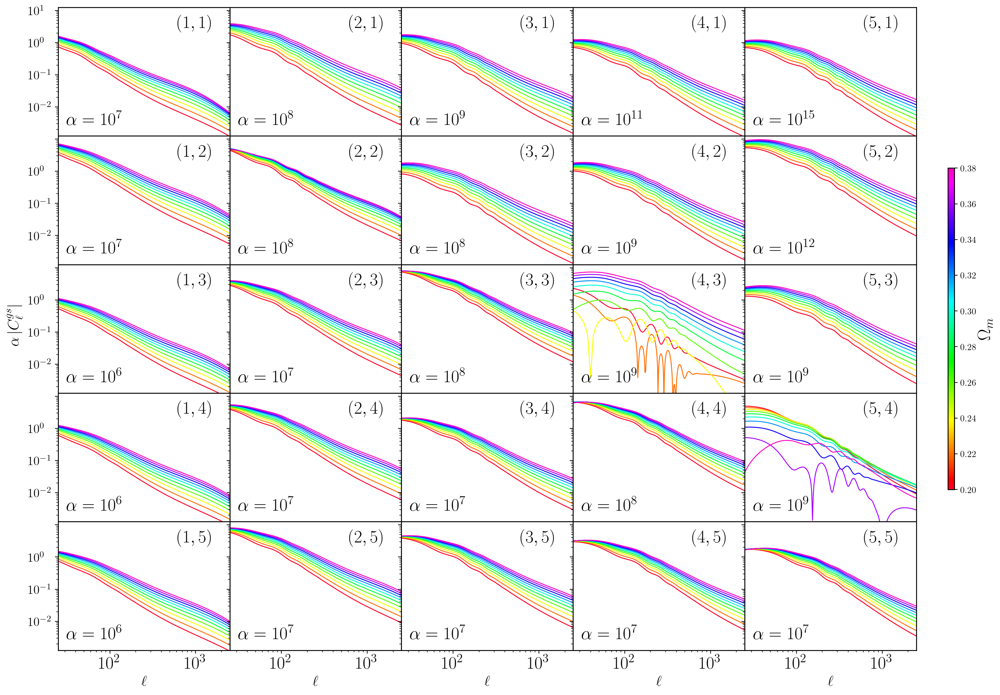

In [16]:
# np.abs: the log axes need |C_gs|, since pairs with little lensing signal can be
# negative through intrinsic alignment.
cnu.plot_C_gs_tomo_limber(ell=ell,
                          C_gs=np.abs(C_gs),
                          param=param,
                          colorbarlabel="$\Omega_m$",
                          bintextpos = [0.8, 0.875],
                          ylim = [0.75,1.3],
                          lmin=ell[0],
                          lmax=ell[len(ell)-1],
                          figsize = (21, 13),
                          bintextsize = 20,
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20,
                          rescale=1,
                          ydecades=4)

In [17]:
ell = np.arange(25., 2500., 3.) # Make sure arange are with float numbers (otherwise there are aliasing problems)
param = np.arange(0.85, 1.1, 0.02)
C_gs = []
for x in param:
    C_gs.append(nw.C_gs_tomo_limber(ell=ell, ns=x))

# Plot the Ratio over ref cosmology
ref = nw.C_gs_tomo_limber(ell=ell)

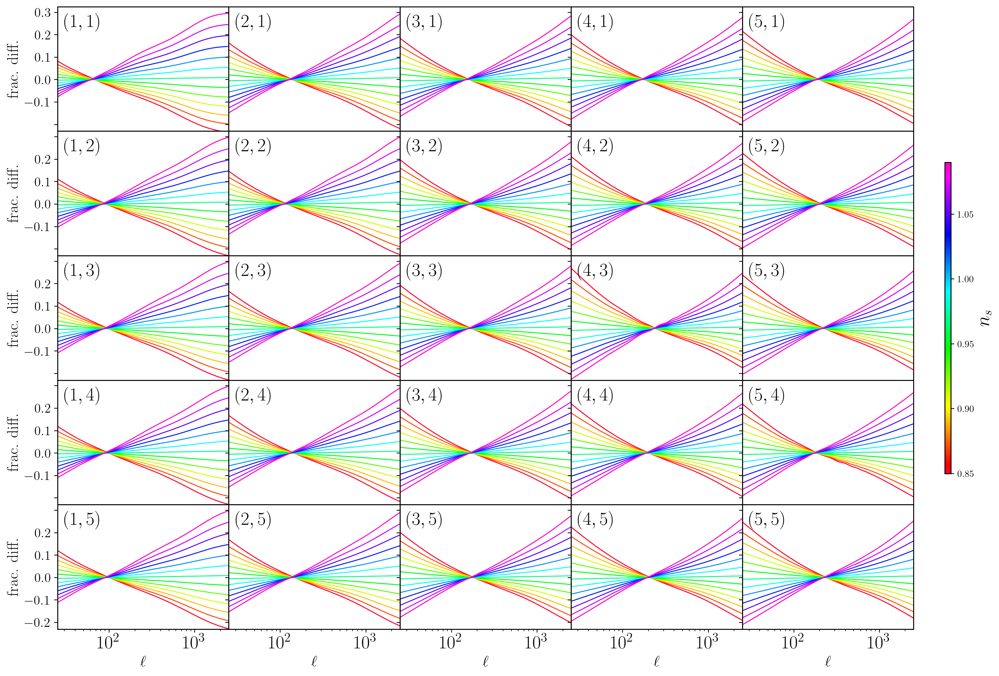

In [18]:
cnu.plot_C_gs_tomo_limber(ell=ell,
                          C_gs=C_gs,
                          C_gs_ref=ref,
                          param=param,
                          colorbarlabel="$n_s$",
                          bintextpos = [0.15, 0.875],
                          ylim = [0.77,1.325],
                          lmin=ell[0],
                          lmax=ell[len(ell)-1],
                          figsize = (20, 12),
                          bintextsize = 20,
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

## 6. Galaxy–galaxy lensing in real space: $\gamma_t(\theta)$

The tangential shear is the transform of $C_\ell^{gs}$ with the Bessel function $J_2$:
$\gamma_t(\theta)=\int\frac{\ell\,d\ell}{2\pi}\,J_2(\ell\theta)\,C_\ell^{gs}$ in the
flat-sky limit, averaged over each angular bin. It measures the mean tangential
distortion of source shapes around lens galaxies. `nw.gamma_t` returns
`(theta, gammat)`, the bin centers in arcmin and an array with axes (angular bin, lens
bin, source bin); it also installs the point-mass amplitudes, zero here.

The next cell repeats the $\Omega_m$ sweep, and the figure shows $|\gamma_t|$ on log
axes, one panel per (lens, source) pair, each with its own $y$ range. Expect the
signal to fall with angle and to rise with $\Omega_m$.

In [19]:
param = np.arange(0.2, 0.4, 0.02)   
gammat_theta = []
for x in param:
    gammat_theta.append(nw.gamma_t(omegam = x))

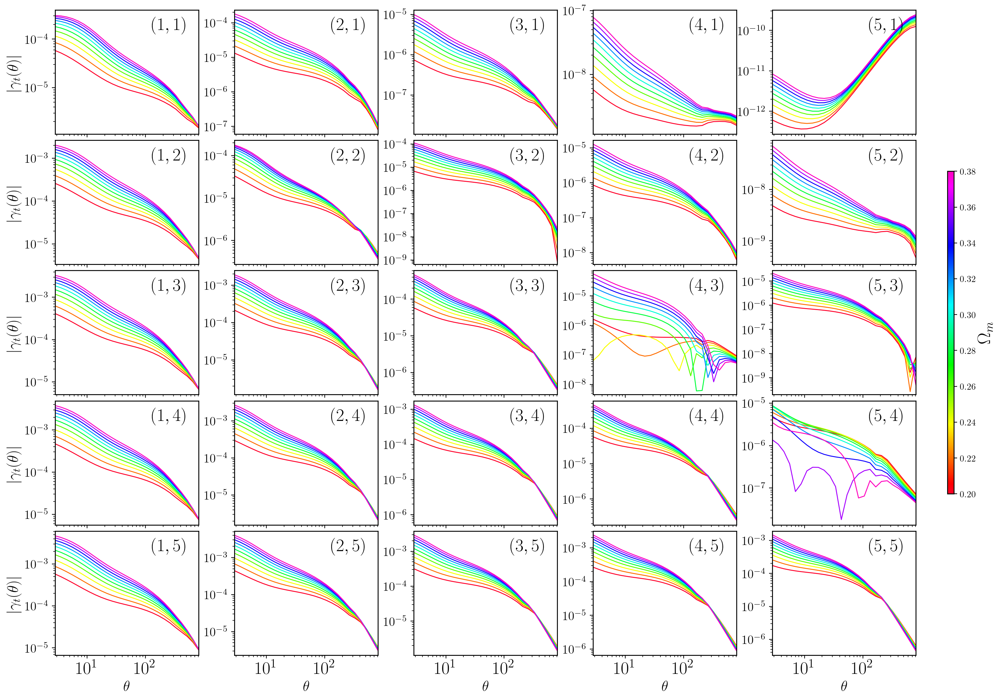

In [20]:
cnu.plot_gammat_tomo_limber(theta_gammat = gammat_theta,
                            gammat_ref = None,
                            param = param,
                            colorbarlabel = "$\Omega_m$",
                            bintextpos = [0.8, 0.875],
                            ylim = [0.75,1.3],
                            figsize = (21, 13),
                            bintextsize = 20,
                            yaxislabelsize = 17,
                            yaxisticklabelsize = 14,
                            xaxisticklabelsize = 20)

## 7. Change the angular binning of $\gamma_t$ without restarting the kernel

CosmoLike computes the bin-averaged Legendre kernels that turn $C_\ell$ into
$\gamma_t$ once per binning and keeps them in static C arrays. `init_binning` marks
them stale, so the next call rebuilds them; if that bookkeeping failed, a new binning
would silently reuse the old kernels. The next cell computes $\gamma_t$ at the
fiducial point with 9, 12, 17 and 44 bins in one session, and the figure draws each
binning with its own marker. All points should trace one curve per panel, up to the
small differences expected from averaging over bins of different widths.

In [21]:
nthetas=[9, 12, 17, 44]
# Each call re-runs init_binning, which marks the cached kernels stale.
gammat_theta = []
for x in nthetas:
    gammat_theta.append(nw.gamma_t(ntheta=x))

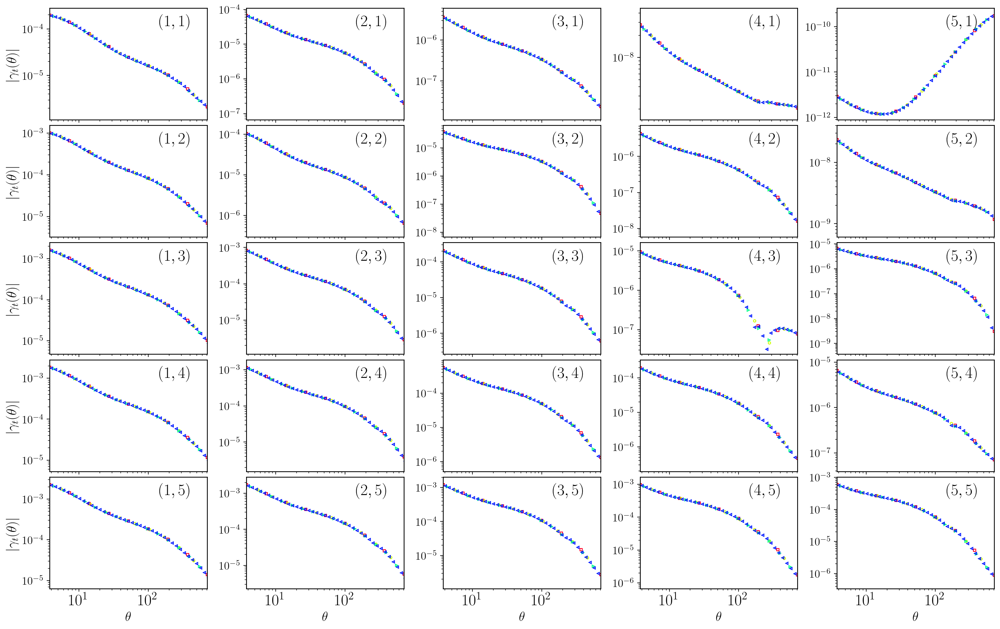

In [22]:
cnu.plot_gammat_tomo_limber(theta_gammat = gammat_theta,
                            marker=['s', 'o', ">", "<"],
                            ylim = [0.75,1.3],
                            bintextpos = [0.8, 0.875],
                            figsize = (21, 13),
                            bintextsize = 20,
                            yaxislabelsize = 17,
                            yaxisticklabelsize = 14,
                            xaxisticklabelsize = 20)

## 8. Baryonic feedback in $C_\ell^{gs}$ and $\gamma_t$

Gas heated and expelled by active galactic nuclei (AGN) and supernovae lowers the
matter power spectrum at $k\gtrsim1\,h/{\rm Mpc}$ relative to a dark-matter-only
universe. With `baryon_sims=<name>`, CosmoLike multiplies $P_{\rm NL}(k,z)$ by the ratio
$P_{\rm hydro}/P_{\rm DMO}$ measured in one hydrodynamical simulation. The nine
simulations of the next cell (TNG100, Horizon-AGN, MassiveBlack-II, Illustris, EAGLE,
three OWLS-AGN variants and BAHAMAS) are read from the HDF5 file named by the dataset,
`baryons_logPkR.h5`; without `baryon_sims` the wrappers remove any contamination.

The next cell computes $C_\ell^{gs}$ for $3\le\ell<7500$ and $\gamma_t$ in 40 angular bins
for every simulation, plus the feedback-free references. The two figures show
value/reference − 1, one line style per simulation, with the legend naming them.
Expect no change at low $\ell$ and large $\theta$, and a suppression that grows toward
high $\ell$ and small $\theta$. The spread between simulations measures how uncertain
the feedback prediction is.

In [23]:
ell = np.arange(3., 7500., 10.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = ("TNG100-1", "HzAGN-1", "mb2-1", "illustris-1", "eagle-1", "owls_AGN-1", "owls_AGN-2", "owls_AGN-3", "BAHAMAS-2")
    
# baryon_sims names a simulation stored in the dataset's HDF5 file.
C_gs = []
for x in param:
    C_gs.append(nw.C_gs_tomo_limber(ell=ell,baryon_sims=x))
    
# Plot the Ratio over ref cosmology
C_gs_ref = nw.C_gs_tomo_limber(ell=ell)

# 40 angular bins give smoother ratio curves than the 26 of the data vector.
gammat_theta = []
for x in param:
    gammat_theta.append(nw.gamma_t(baryon_sims=x, ntheta=40, AccuracyBoost=1.0))
gammat_theta_ref = nw.gamma_t(ntheta=40, AccuracyBoost=1.0)

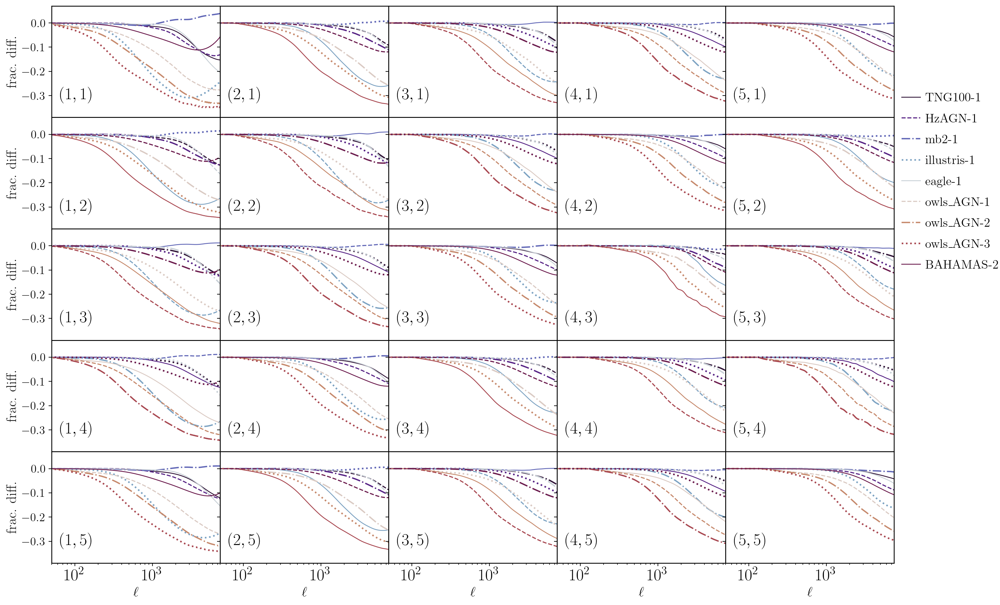

In [24]:
# A global change: every later legend of the notebook uses this font size.
matplotlib.rcParams['legend.fontsize'] = 15
cnu.plot_C_gs_tomo_limber(ell=ell,
                          C_gs=C_gs,
                          C_gs_ref=C_gs_ref,
                          lmin=50,
                          lmax=ell[len(ell)-1],
                          cmap="twilight_shifted",
                          bintextpos = [0.15, 0.2],
                          ylim = [0.61,1.07],
                          legend = param,
                          legendloc=(0.9,0.55),
                          linewidth=[1.0, 1.3, 1.6, 1.9],
                          linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                          figsize = (18, 12),
                          bintextsize = 20,
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

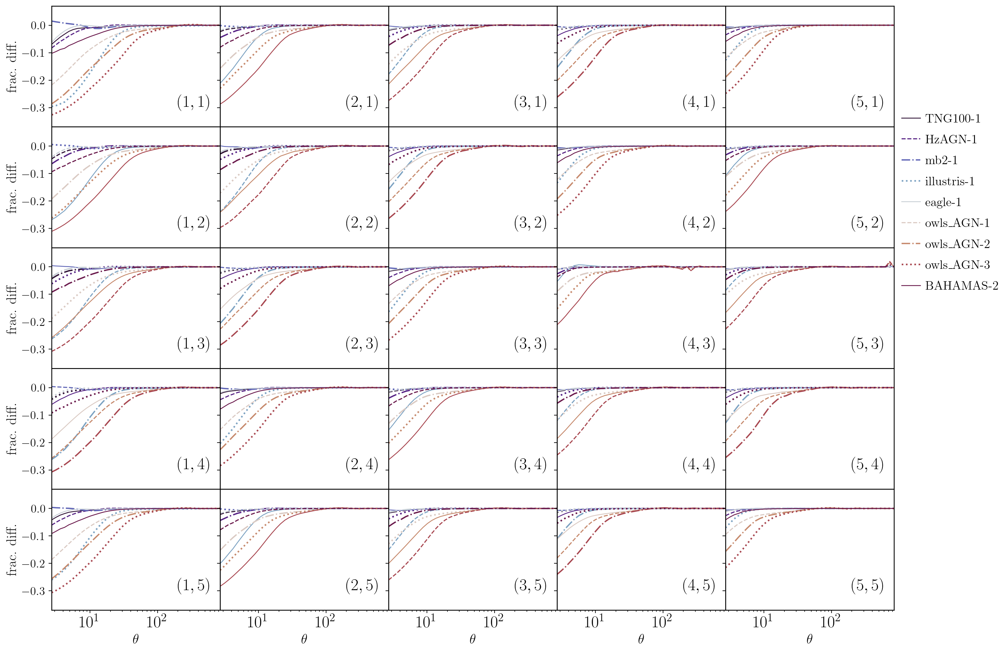

In [25]:
cnu.plot_gammat_tomo_limber(theta_gammat=gammat_theta,
                            gammat_ref=gammat_theta_ref,
                            cmap="twilight_shifted",
                            bintextpos = [0.85, 0.2],
                            ylim = [0.63,1.07],
                            legend = param,
                            legendloc=(0.9,0.55),
                            linewidth=[1.0, 1.3, 1.6, 1.9],
                            linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                            figsize = (18, 13),
                            bintextsize = 20,
                            yaxislabelsize = 17,
                            yaxisticklabelsize = 14,
                            xaxisticklabelsize = 20)

## 9. Numerical accuracy of $C_\ell^{gs}$ and $\gamma_t$

Four arguments set the numerical accuracy of every wrapper call:

| Argument | What it refines |
| --- | --- |
| `CAMBAccuracyBoost` | CAMB's internal accuracy, its largest wavenumber and its $k$ sampling |
| `CLAccuracyBoost` | CosmoLike's interpolation tables and integration grids, and the length of its $C_\ell$ table |
| `CLIntegrationAccuracy` | the quadrature rule of CosmoLike's integrals (an integer level) |
| `AccuracyBoost` | both sides at once: it multiplies `CLAccuracyBoost` and gives a third of its excess over one to CAMB |

The next cell raises CAMB and CosmoLike accuracy together, with CAMB boost $1+x/3$,
CosmoLike boost $1+x$ and integration level $\lfloor x\rfloor$, and compares with the
default settings. The two figures show value/reference − 1 in a band of ±1.9%; the
color bar gives $x$. Converged settings make the curves collapse onto each other: the
spread among the highest values of $x$ shows the remaining numerical error, and their
offset from zero the error of the defaults.

In [26]:
ell = np.arange(10., 8500., 30.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0,6.0,0.5)

# x raises CAMB accuracy (1 + x/3) and CosmoLike accuracy (1 + x) together.
C_gs = []
for x in param:
    C_gs.append(nw.C_gs_tomo_limber(ell=ell,AccuracyBoost=1.0,CAMBAccuracyBoost=1.+x/3.,CLAccuracyBoost=1+x,CLIntegrationAccuracy=int(x)))
    
# Plot the Ratio over ref cosmology
C_gs_ref = nw.C_gs_tomo_limber(ell=ell,AccuracyBoost=1.0,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0)

gammat_theta = []
for x in param:
    gammat_theta.append(nw.gamma_t(ntheta=40,AccuracyBoost=1.0,CAMBAccuracyBoost=1.+x/3.,CLAccuracyBoost=1+x,CLIntegrationAccuracy=int(x)))
gammat_theta_ref = nw.gamma_t(ntheta=40,AccuracyBoost=1.0,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0)

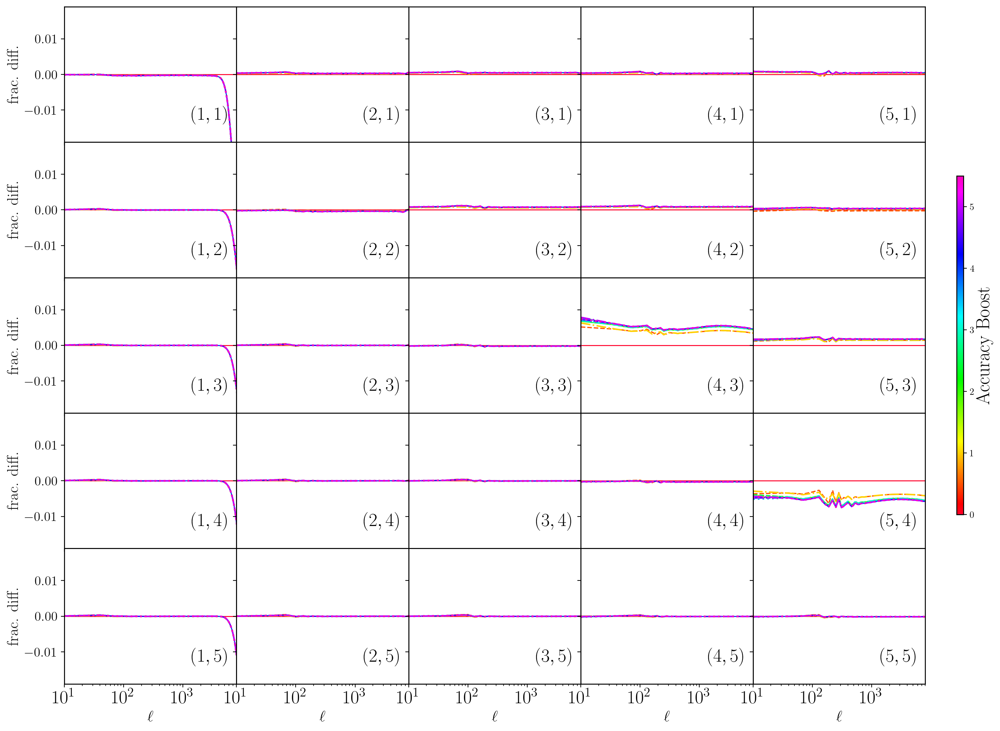

In [27]:
cnu.plot_C_gs_tomo_limber(ell=ell,
                          C_gs=C_gs,
                          C_gs_ref=C_gs_ref,
                          param=param,
                          lmin=10,
                          lmax=8000,
                          ylim=(0.981,1.019),
                          bintextpos = [0.85, 0.2],
                          colorbarlabel="Accuracy Boost",
                          linewidth=[1.0, 1.3, 1.6, 1.9],
                          linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                          figsize = (20, 13),
                          bintextsize = 20,
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

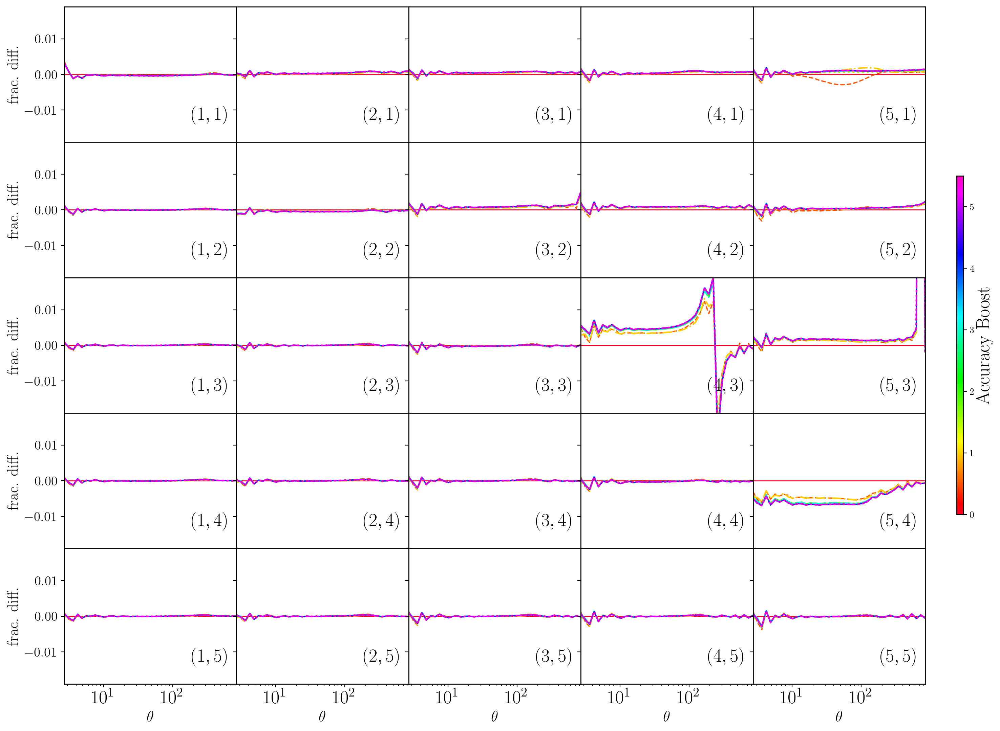

In [28]:
cnu.plot_gammat_tomo_limber(theta_gammat=gammat_theta,
                            gammat_ref=gammat_theta_ref,
                            bintextpos = [0.85, 0.2],
                            ylim = (0.981,1.019),
                            param=param,
                            legendloc=(0.9,0.55),
                            colorbarlabel="Accuracy Boost",
                            linewidth=[1.0, 1.3, 1.6, 1.9],
                            linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                            figsize = (20, 13),
                            bintextsize = 20,
                            yaxislabelsize = 17,
                            yaxisticklabelsize = 14,
                            xaxisticklabelsize = 20)

## 10. Galaxy clustering in harmonic space: Limber and non-Limber $C_\ell^{gg}$

The auto-spectrum of lens bin $i$ is, in the Limber approximation,

$$C_\ell^{ii}=\int d\chi\,\frac{\left[b_1^i\,n_i(\chi)\right]^2}{\chi^2}\,P_{\rm NL}\!\left(k=\frac{\ell+1/2}{\chi},\,z(\chi)\right).$$

The exact expression integrates the power spectrum against a product of two
spherical Bessel functions along the line of sight; CosmoLike evaluates it below an
$\ell$ threshold with the FFTLog algorithm, a fast transform for such integrals on
logarithmic grids, and uses Limber above it. For narrow lens bins the two differ at low
$\ell$, where a bin spans few wavelengths.

- The next two cells compute both versions for the $\Omega_m$ sweep and draw them as
  two rows of five panels: Limber first, then non-Limber.
- The two cells after them compute the ratio non-Limber / Limber for $3\le\ell<250$ and
  draw it on a linear axis, for $3\le\ell\le120$. Expect departures from one at the
  lowest multipoles that shrink as $\ell$ grows.

In [29]:
ell = np.arange(3., 2500., 3.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.2, 0.4, 0.02)
C_gg_L = []
C_gg_NL = []
ratio = []
for x in param:
    tmp1 = nw.C_gg_tomo(ell=ell, limber=1, omegam=x)
    tmp2 = nw.C_gg_tomo(ell=ell, limber=0, omegam=x)
    C_gg_L.append(tmp1)
    C_gg_NL.append(tmp2)

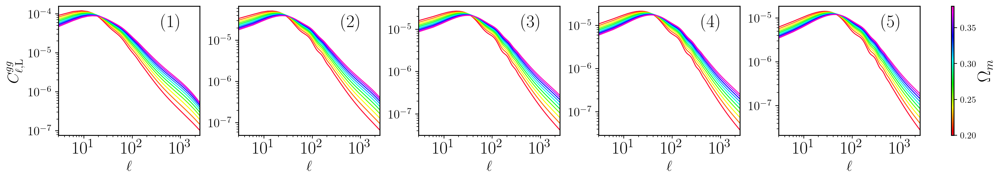

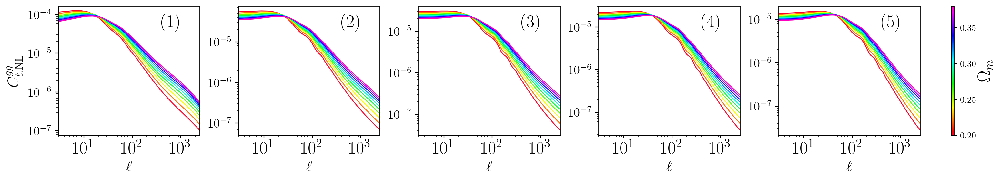

In [30]:
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=C_gg_L,
                   param=param,
                   colorbarlabel="$\Omega_m$",
                   bintextpos = [0.8, 0.875],
                   ylim = [0.75,1.3],
                   lmin=ell[0],
                   lmax=ell[len(ell)-1],
                   overwriteylabel="$C_{\ell,{\\rm L}}^{gg}$",
                   figsize = (21, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=C_gg_NL,
                   param=param,
                   colorbarlabel="$\Omega_m$",
                   bintextpos = [0.8, 0.875],
                   ylim = [0.75,1.3],
                   lmin=ell[0],
                   lmax=ell[len(ell)-1],
                   overwriteylabel="$C_{\ell,{\\rm NL}}^{gg}$",
                   figsize = (21, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)

In [31]:
ell = np.arange(3., 250., 1.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.2, 0.4, 0.02)
ratio = []
for x in param:
    tmp1 = nw.C_gg_tomo(ell=ell, limber=1, omegam=x)
    tmp2 = nw.C_gg_tomo(ell=ell, limber=0, omegam=x)
    ratio.append(tmp2/tmp1)

/var/folders/8m/fbnlt6rs00g8g5nshfw27mfw0000gn/T/ipykernel_76429/4250613529.py:7: RuntimeWarning: invalid value encountered in divide
  ratio.append(tmp2/tmp1)


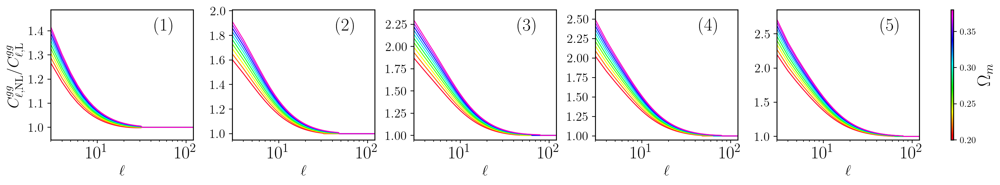

In [32]:
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=ratio,
                   param=param,
                   colorbarlabel="$\Omega_m$",
                   bintextpos = [0.8, 0.875],
                   ylim = [0.95,1.05],
                   lmin=3,
                   lmax=120,
                   forcelinearyscale=True,
                   overwriteylabel="$C_{\ell,{\\rm NL}}^{gg}/C_{\ell,{\\rm L}}^{gg}$",
                   forcelinearxscale=False,
                   marker=None,
                   figsize = (21, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)

## 11. Galaxy clustering in real space: $w(\theta)$

The angular correlation function is the Legendre transform of $C_\ell^{gg}$, averaged
over each angular bin; at low $\ell$ it uses the non-Limber spectra of section 10, as the
likelihood does. `nw.w_theta` returns `(theta, wtheta)`: the bin centers in arcmin
and an array with axes (angular bin, lens bin, lens bin), of which only the
auto-correlations are filled. The next cell repeats the $\Omega_m$ sweep, and the
figure shows $|w(\theta)|$ on log axes, one panel per lens bin; a dip in $|w|$ can mark
a sign change at large angles.

In [33]:
param = np.arange(0.2, 0.4, 0.02)   
wtheta_theta = []
for x in param:
    wtheta_theta.append(nw.w_theta(omegam = x))

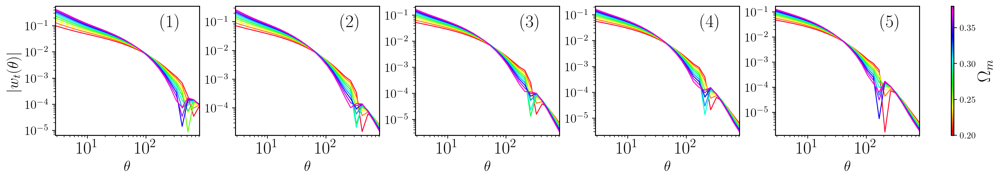

In [34]:
cnu.plot_wtheta_tomo(theta_wtheta = wtheta_theta,
                     theta_wtheta_ref = None,
                     param = param,
                     colorbarlabel = "$\Omega_m$",
                     bintextpos = [0.8, 0.875],
                     ylim = [0.75,1.3],
                     figsize = (21, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20)

## 12. Change the angular binning of $w(\theta)$

The same cache test as section 7, for clustering: $w(\theta)$ at the fiducial point
with 9, 12, 17 and 44 bins in one session. All points should trace one curve per
panel, up to the small differences expected from averaging over bins of different
widths.

In [35]:
nthetas=[9, 12, 17, 44]
# Each call re-runs init_binning, which marks the cached kernels stale.
wtheta_theta = []
for x in nthetas:
    wtheta_theta.append(nw.w_theta(ntheta=x))

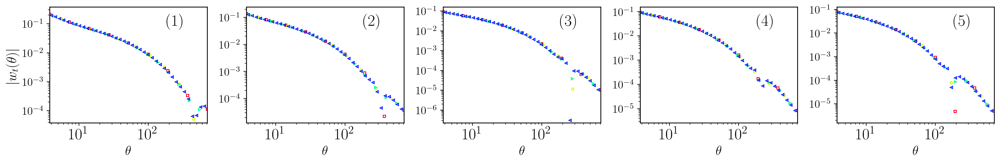

In [36]:
cnu.plot_wtheta_tomo(theta_wtheta=wtheta_theta,
                     marker=['s', 'o', ">", "<"],
                     ylim = [0.75,1.3],
                     bintextpos = [0.8, 0.875],
                     figsize = (21, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20)

## 13. Baryonic feedback in $C_\ell^{gg}$ and $w(\theta)$

The feedback models of section 8 applied to clustering: non-Limber $C_\ell^{gg}$ for
$3\le\ell<7500$ and $w(\theta)$ in 40 angular bins, for each simulation. The next cell
computes them, and the cell after it draws both ratio figures, value/reference − 1.
Expect a suppression at high $\ell$ and small $\theta$ in every lens bin.

In [37]:
ell = np.arange(3., 7500., 10.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = ("TNG100-1", "HzAGN-1", "mb2-1", "illustris-1", "eagle-1", "owls_AGN-1", "owls_AGN-2", "owls_AGN-3", "BAHAMAS-2")
    
# Non-Limber spectra, as in the likelihood's real-space clustering.
C_gg = []
for x in param:
    C_gg.append(nw.C_gg_tomo(ell=ell,limber=False,baryon_sims=x))
    
# Plot the Ratio over ref cosmology
C_gg_ref = nw.C_gg_tomo(ell=ell,limber=False)

wtheta_theta = []
for x in param:
    wtheta_theta.append(nw.w_theta(baryon_sims=x, ntheta=40, AccuracyBoost=1.0))
wtheta_theta_ref = nw.w_theta(ntheta=40, AccuracyBoost=1.0)

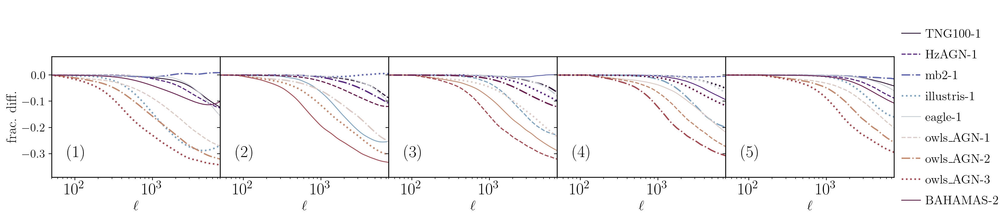

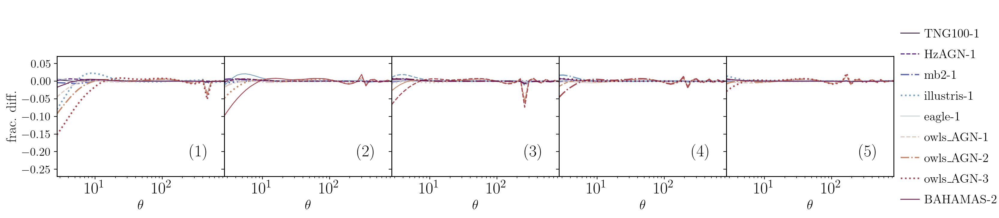

In [38]:
matplotlib.rcParams['legend.fontsize'] = 15
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=C_gg,
                   C_gg_ref=C_gg_ref,
                   lmin=50,
                   lmax=ell[len(ell)-1],
                   cmap="twilight_shifted",
                   bintextpos = [0.15, 0.2],
                   ylim = [0.61,1.07],
                   legend = param,
                   legendloc=(0.9,0.05),
                   linewidth=[1.0, 1.3, 1.6, 1.9],
                   linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                   figsize = (18, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)
cnu.plot_wtheta_tomo(theta_wtheta=wtheta_theta,
                     theta_wtheta_ref=wtheta_theta_ref,
                     cmap="twilight_shifted",
                     bintextpos = [0.85, 0.2],
                     ylim = [0.73,1.07],
                     legend = param,
                     legendloc=(0.9,0.05),
                     linewidth=[1.0, 1.3, 1.6, 1.9],
                     linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                     figsize = (18, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20)

## 14. Numerical accuracy of $C_\ell^{gg}$ and $w(\theta)$

The joint accuracy sweep of section 9 for clustering. For non-Limber $C_\ell^{gg}$ the
sweep runs over $x=0.6,1.1,\dots,5.6$ against the default settings, in a band of
±1.5%. The last cell repeats it for $w(\theta)$ in 80 angular bins, starting from
`CAMBAccuracyBoost` = 1.2 instead of 1: its comment records that $w(\theta)$ needs
this higher CAMB accuracy as a baseline. The band there is ±2.5%.

In [39]:
ell = np.arange(10., 8500., 30.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.6,6.0,0.5)
C_gg = []
for x in param:
    C_gg.append(nw.C_gg_tomo(ell=ell,limber=False,AccuracyBoost=1,CAMBAccuracyBoost=1.+x/3,CLAccuracyBoost=1+x,CLIntegrationAccuracy=int(x)))
    
# Plot the Ratio over ref cosmology
C_gg_ref = nw.C_gg_tomo(ell=ell,limber=False,AccuracyBoost=1,CAMBAccuracyBoost=1.,CLAccuracyBoost=1,CLIntegrationAccuracy=0)

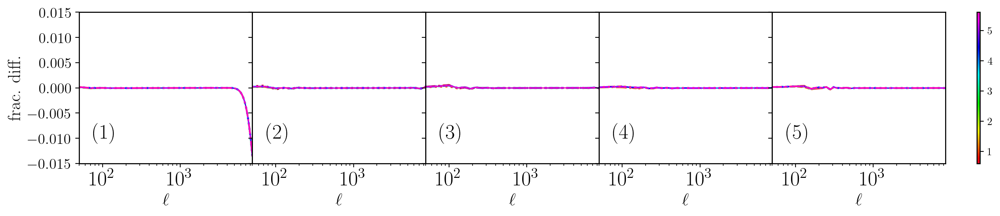

In [40]:
matplotlib.rcParams['legend.fontsize'] = 15
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=C_gg,
                   C_gg_ref=C_gg_ref,
                   lmin=50,
                   lmax=ell[len(ell)-1],
                   bintextpos = [0.15, 0.2],
                   ylim = [0.985,1.015],
                   param = param,
                   legendloc=(0.9,0.05),
                   linewidth=[1.0, 1.3, 1.6, 1.9],
                   linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                   figsize = (18, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)

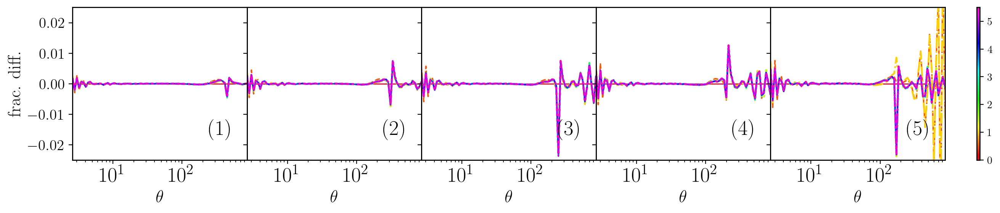

In [41]:
# w(theta) needs CAMBAccuracyBoost of at least 1.2: the reference and every
# curve of this sweep start from that value.
param = np.arange(0,6.0,0.5)

wtheta_theta = []
for x in param:
    wtheta_theta.append(nw.w_theta(ntheta=80,AccuracyBoost=1,CAMBAccuracyBoost=1.2+x/3,CLAccuracyBoost=1.0+x,CLIntegrationAccuracy=int(x)))
wtheta_theta_ref = nw.w_theta(ntheta=80,AccuracyBoost=1,CAMBAccuracyBoost=1.2,CLAccuracyBoost=1.0,CLIntegrationAccuracy=0)
  
cnu.plot_wtheta_tomo(theta_wtheta=wtheta_theta,
                     theta_wtheta_ref=wtheta_theta_ref,
                     ylim = [0.975,1.025],
                     bintextpos = [0.85, 0.2],
                     param = param,
                     legendloc=(0.9,0.05),
                     linewidth=[1.0, 1.3, 1.6, 1.9],
                     linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                     figsize = (18, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20)

## 15. $\chi^2$ of the 3×2pt data vector

The next cell initializes the interface again with the 3×2pt probes and with the
covariance, mask and data vector of the dataset. `nw.get_chi2` computes the masked
theory vector $m$ and

$$\chi^2=(d-m)^{\mathsf T}\,C^{-1}\,(d-m)$$

over the 959 unmasked entries, where $d$ is the stored data vector and $C$ the LSST Y1
covariance. The stored data vector is a noiseless prediction close to this notebook's
fiducial point, so the printed $\chi^2$ is well below one.

In [42]:
# Re-init with the chi2 machinery: probes, covariance, mask, and
# data vector (nw.init_cosmolike holds the full sequence; get_chi2
# lives in the wrappers module, call it as nw.get_chi2)
ini = nw.init_cosmolike(CLprobe="3x2pt", with_data=True)

In [43]:
print(rf"$\chi^2$={nw.get_chi2():3.3f}")

$\chi^2$=0.267


## 16. $\chi^2$ as a function of accuracy

The convergence metric of this project is $\Delta\chi^2$, the change of $\chi^2$ between
a setting and a more accurate one; the project's frozen tests accept
$|\Delta\chi^2|<0.2$. The next cell raises CAMB and CosmoLike accuracy together (CAMB
boost $1+x/3$, CosmoLike boost $1+x$, integration level $\lfloor x\rfloor$), and the
plot shows $\chi^2(x)-\chi^2(x_{\max})$ against $x$. Expect the curve to approach zero
as $x$ grows; its value at $x=0$ estimates the error of the default settings.

In [44]:
param = np.arange(0,6,0.5)      
chi2 = []
for x in param:
    chi2.append(nw.get_chi2(AccuracyBoost=1,CAMBAccuracyBoost=1.+x/3,CLAccuracyBoost=1+x,CLIntegrationAccuracy=int(x)))
chi2 = np.array(chi2)

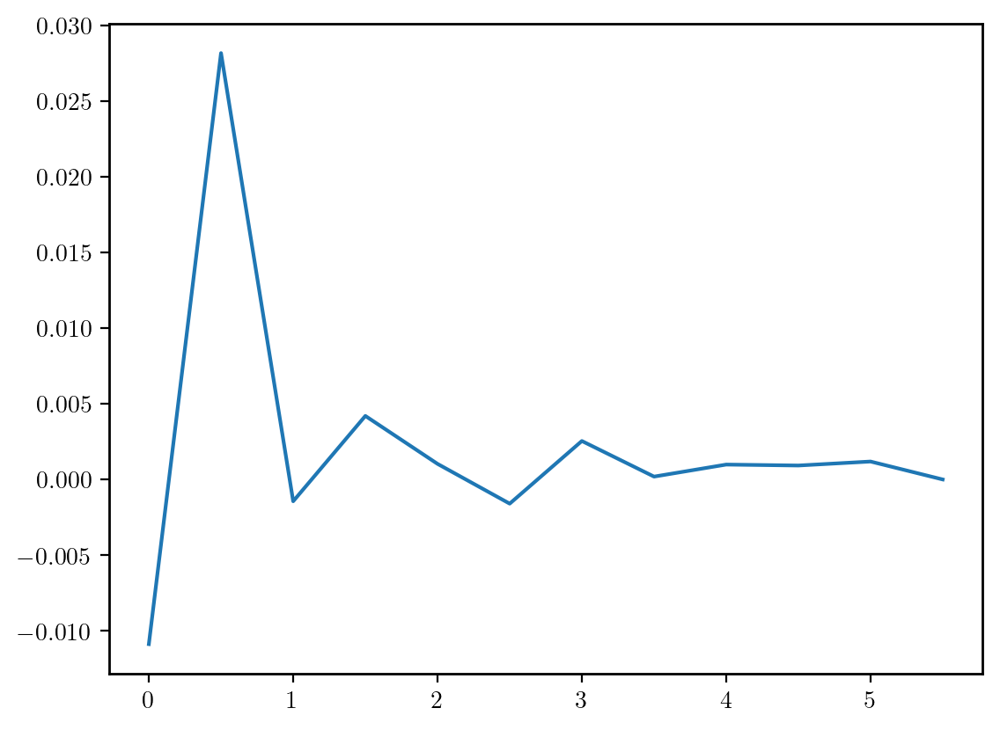

In [45]:
# x: accuracy variable, y: Delta chi2 relative to the last, most accurate entry.
plt.plot(param, np.array(chi2-chi2[-1]))

## 17. Halofit versus EuclidEmulator2

Two prescriptions give the nonlinear matter power spectrum. Halofit (here its
Takahashi et al. 2012 version, `non_linear_emul=2`, the default) is a fitting formula
calibrated on N-body simulations. EuclidEmulator2 (`non_linear_emul=1`) is an emulator
of the nonlinear boost $P_{\rm NL}/P_{\rm lin}$ trained on a suite of N-body
simulations; it is used below $z=10$, and halofit above.

The next cell prints the 3×2pt $\chi^2$ with EuclidEmulator2, then with halofit. The
stored data vector was made with halofit, so the second value is close to zero and the
first measures how far the choice of model alone moves the fit. The following cells
compare $w(\theta)$ in 80 bins, at `CAMBAccuracyBoost` = 1.2: the curve is halofit and
the reference EuclidEmulator2, in a band of ±10%.

In [46]:
# non_linear_emul = 1: EuclidEmulator2; 2: halofit, the model of the stored data.
print(rf"$\chi^2$={nw.get_chi2(non_linear_emul=1):3.3f}")
print(rf"$\chi^2$={nw.get_chi2(non_linear_emul=2):3.3f}")

/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/euclidemu2/ee2_bindata.dat
$\chi^2$=15.269


$\chi^2$=0.267


In [47]:
# w(theta) uses CAMBAccuracyBoost = 1.2 as its baseline (section 14). Curve:
# halofit (non_linear_emul=2); reference: EuclidEmulator2.
param = [1]
wtheta_theta = []
for x in param:
    wtheta_theta.append(nw.w_theta(ntheta=80,AccuracyBoost=1,CAMBAccuracyBoost=1.2,CLAccuracyBoost=1,CLIntegrationAccuracy=0,non_linear_emul=2))
wtheta_theta_ref = nw.w_theta(ntheta=80,AccuracyBoost=1,CAMBAccuracyBoost=1.2,CLAccuracyBoost=1,CLIntegrationAccuracy=0,non_linear_emul=1)

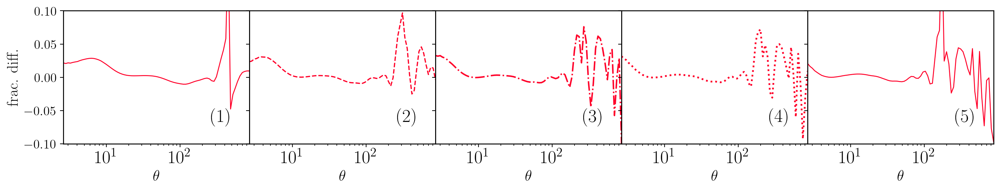

In [48]:
cnu.plot_wtheta_tomo(theta_wtheta=wtheta_theta,
                     theta_wtheta_ref=wtheta_theta_ref,
                     ylim = [0.9,1.1],
                     bintextpos = [0.85, 0.2],
                     param = param,
                     legendloc=(0.9,0.05),
                     linewidth=[1.0, 1.3, 1.6, 1.9],
                     linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                     figsize = (18, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20,
                     colorbar=None)

## 18. Fisher forecast of the prior cuts

`EXAMPLE_EVALUATE2.yaml` cuts its prior to keep a sampler out of corners where the
numerical error of the data vector grows (the accuracy FAQ of the README): boxes on
$\Omega_\mathrm{m}$ and $w_0$, a wall on $w_0 + w_a$, and an amplitude cut on
$10^9 A_\mathrm{s}$ and the lens biases. Here $A_\mathrm{s}$ is the primordial
amplitude, sampled as `As_1e9` $= 10^9 A_\mathrm{s}$, and $b_i$ is the linear galaxy
bias of lens bin $i$ (`LSST_B1_i`). This section checks the cuts against what the
3×2pt data can actually constrain.

A Fisher forecast is a Gaussian approximation of the posterior around the fiducial
model: the derivatives of the data vector with respect to the parameters, weighted by
the inverse of the data covariance, give the Fisher matrix $F$, and $F^{-1}$
approximates the parameter covariance of the posterior. The $2\sigma$ contours drawn
from $F^{-1}$ outline the region the data allow, so a cut far outside them removes
only prior volume the data already exclude and cannot shape the posterior; a cut that
crosses them would.

The matrix varies 29 parameters: $10^9 A_\mathrm{s}$, $n_\mathrm{s}$, $H_0$,
$\Omega_\mathrm{b}$, $\Omega_\mathrm{m}$, $w_0$ and $w_a$, plus 22 nuisances — the
two NLA intrinsic-alignment parameters, five source and five lens photo-z shifts,
five shear calibrations and the five lens biases $b_i$. The yaml's Gaussian priors
sit on 15 of the nuisances (the photo-z shifts and the shear calibrations) and enter
$F$ directly. The neutrino mass is fixed, and the TATT parameters the yaml samples
are left out because the NLA data vector does not depend on them.

The fiducial is the yaml's evaluate point ($w_0 = -0.9$, $w_a = 0$). Each derivative
is a five-point stencil (`cnu.get_ddv`) with the relative step $h = 0.025$, at the
yaml's own accuracy settings; $\gamma_t$ is computed non-Limber below $\ell = 150$,
exactly as in the likelihood.

In [49]:
# Inputs of the forecast: the varied parameters, their fiducial values, the
# Gaussian priors, the accuracy settings and the stencil step. They are read
# from EXAMPLE_EVALUATE2.yaml and from the parameter files of its likelihood,
# so the forecast and the figures follow the prior the yaml applies.
import pickle
import time
from cobaya.yaml import yaml_load_file

LSST_Y1_DIR = os.environ['ROOTDIR'] + '/projects/lsst_y1/'
FISHER_YAML = LSST_Y1_DIR + 'EXAMPLE_EVALUATE2.yaml'
example = yaml_load_file(FISHER_YAML)
# the nuisance priors live in the likelihood's parameter files; an entry of
# the example's params block replaces the file's entry, as in cobaya
likelihood_params = {}
for file_name in ('params_lens.yaml', 'params_source.yaml'):
    likelihood_params.update(
        yaml_load_file(LSST_Y1_DIR + 'likelihood/' + file_name))


def example_prior(name):
    '''Return the prior of one parameter as the example yaml applies it.

    Arguments:
      name = a parameter name of the yaml (As_1e9, w, w0pwa, LSST_B1_1, ...).

    Returns:
      dict: the prior block of the example's params entry for name, or of
      the likelihood's parameter files when the example has no entry.

    Raises:
      KeyError when no file names the parameter, or when its entry has no
      prior (a fixed or derived parameter, which cannot be varied).
    '''
    if name in example['params']:
        entry = example['params'][name]
    elif name in likelihood_params:
        entry = likelihood_params[name]
    else:
        raise KeyError(f'{name} is not a parameter of {FISHER_YAML} or of '
                       'likelihood/params_lens.yaml and params_source.yaml')
    if 'prior' not in entry:
        raise KeyError(f'{name} has no prior block: it is fixed or derived '
                       'in the example, so it cannot be a Fisher parameter')
    return entry['prior']


# The varied parameters, in the order of the Fisher matrix: the seven
# cosmological parameters (w0 = the yaml's w, wa = w0pwa - w) and every
# nuisance parameter of the NLA 3x2pt vector. mnu stays at 0.06 eV, the
# lower edge of its box, where a two-sided derivative leaves the prior.
# LSST_A2_1, LSST_A2_2 and LSST_BTA_1, which the yaml samples, are TATT
# parameters: the NLA vector does not depend on them.
FISHER_NAMES = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa',
                'LSST_A1_1', 'LSST_A1_2']
for prefix in ('LSST_DZ_S', 'LSST_M', 'LSST_DZ_L', 'LSST_B1_'):
    for i in range(1, 6):
        FISHER_NAMES.append(prefix + str(i))

# the fiducial point: the evaluate point of the yaml (the values of the
# wrappers module, imported in section 2), with w0 = w and wa = w0pwa - w
override = example['sampler']['evaluate']['override']
fiducial = {}
for name in FISHER_NAMES:
    if name == 'w0':
        fiducial[name] = float(override['w'])
    elif name == 'wa':
        fiducial[name] = float(override['w0pwa'] - override['w'])
    else:
        fiducial[name] = float(override[name])
FISHER_FIDUCIAL = np.zeros(len(FISHER_NAMES))
for index in range(len(FISHER_NAMES)):
    FISHER_FIDUCIAL[index] = fiducial[FISHER_NAMES[index]]

# Gaussian priors {index: (mean, sigma)}, centered on the fiducial as in
# nw.FISHER_GAUSSIAN_PRIORS. The widths come from the likelihood parameter
# files: 0.002 for the source photo-z shifts, 0.005 for the lens shifts and
# the shear calibrations. A flat prior adds nothing to F; w0 and w0 + wa
# have flat boxes, and wa has no prior of its own.
fisher_gaussian_priors = {}
for index in range(len(FISHER_NAMES)):
    name = FISHER_NAMES[index]
    if name in ('w0', 'wa'):
        continue
    prior = example_prior(name)
    if prior.get('dist') == 'norm':
        fisher_gaussian_priors[index] = (fiducial[name], float(prior['scale']))

# The example's own accuracy, with no extra boost: CAMB's extra_args and the
# likelihood's accuracyboost, integration_accuracy, non_linear_emul and lmax.
# cnu.get_camb_cosmology scales kmax and k_per_logint with the CAMB boost
# (to 8.6/Mpc and 16 at 1.05); cobaya's CAMB does not.
camb_args = example['theory']['camb']['extra_args']
likelihood_args = example['likelihood']['lsst_y1.combo_3x2pt']
FISHER_ACCURACY = {
    'kmax': float(camb_args['kmax']),
    'k_per_logint': int(camb_args['k_per_logint']),
    'CAMBAccuracyBoost': float(camb_args['AccuracyBoost']),
    'CLAccuracyBoost': float(likelihood_args['accuracyboost']),
    'CLIntegrationAccuracy': int(likelihood_args['integration_accuracy']),
    'non_linear_emul': int(likelihood_args['non_linear_emul']),
}
FISHER_LMAX = int(likelihood_args['lmax'])
# The likelihood's projection choices (likelihood/combo_3x2pt.yaml, which the
# example's likelihood block overrides): 0 = non-Limber below l = 150, the
# likelihood default for both. nw.init_cosmolike leaves them at the interface
# defaults, and the interface default for galaxy-galaxy lensing is Limber at
# every multipole, so the section sets them itself.
likelihood_defaults = yaml_load_file(LSST_Y1_DIR + 'likelihood/combo_3x2pt.yaml')
FISHER_PROJECTION = {}
for key in ('adopt_limber_gs', 'adopt_limber_gg'):
    if key in likelihood_args:
        FISHER_PROJECTION[key] = int(likelihood_args[key])
    else:
        FISHER_PROJECTION[key] = int(likelihood_defaults[key])
# the relative stencil step of the first Fisher matrix of
# EXAMPLE_EVALUATE1.ipynb; wa, whose fiducial is zero, takes it as an
# absolute step
FISHER_H = 0.025
# the largest amplitude ratio (As/As_fid)(b_i/b_i,fid)^2 that the yaml's
# amplitude_cut prior keeps; the figure cell checks it against the yaml
AMPLITUDE_CUT = 8.0
FISHER_CACHE = LSST_Y1_DIR + 'chains/EXAMPLE_EVALUATE2_FISHER_3x2pt.pkl'
RECOMPUTE = False
# the figures of this section switch LaTeX off; the last cell restores this
USETEX_OUTSIDE_SECTION = matplotlib.rcParams['text.usetex']

# labels of the parameters the figures show; the bias labels are the yaml's
FISHER_LABELS = {
    'As_1e9': r'10^9 A_\mathrm{s}',
    'omegam': r'\Omega_\mathrm{m}',
    'w0': r'w_0',
    'wa': r'w_a',
}
BIAS_NAMES = []
for i in range(1, 6):
    BIAS_NAMES.append('LSST_B1_' + str(i))
    FISHER_LABELS['LSST_B1_' + str(i)] = likelihood_params['LSST_B1_' + str(i)]['latex']
print(len(FISHER_NAMES), 'parameters,', len(fisher_gaussian_priors),
      'with Gaussian priors')

29 parameters, 15 with Gaussian priors


In [50]:
def bin_values(values, prefix):
    '''Return the five per-bin values of one nuisance family.

    Arguments:
      values = {parameter name: value} of one Fisher evaluation.
      prefix = the family's name prefix (LSST_DZ_S, LSST_M, LSST_DZ_L or
               LSST_B1_); the bins are prefix1 to prefix5.

    Returns:
      1D float64 array of 5 entries, bins 1 to 5.
    '''
    entries = np.zeros(5)
    for i in range(5):
        entries[i] = values[prefix + str(i + 1)]
    return entries


def get_dv_3x2pt(param, AccuracyBoost=1.0):
    '''Return the masked 3x2pt data vector at one Fisher parameter vector.

    nw.get_dv, the vector of the forecasts of EXAMPLE_EVALUATE1.ipynb,
    holds w0 = -1 and wa = 0 and sets the shear state only. This function
    sets the full 3x2pt state through nw._set_state, the body of every nw
    wrapper, with w = w0 and w0pwa = w0 + wa, at the example's accuracy
    (FISHER_ACCURACY, and the yaml's lmax FISHER_LMAX for the C_ell tables).
    The projection choices (FISHER_PROJECTION) are interface state that
    compute_fisher_3x2pt sets before the first call.
    The nuisances that are not varied keep the wrappers' fiducial values:
    no TATT terms, higher-order bias, magnification or point mass.
    cnu.get_ddv calls it four times per parameter.

    Arguments:
      param = 1D float array of the FISHER_NAMES values, in that order.
      AccuracyBoost = overall boost on top of FISHER_ACCURACY, as in
              cnu.get_camb_cosmology (1 = the example's settings).

    Returns:
      1D float64 array: the masked data vector (masked entries 0), in the
      order of the dataset's data-vector file.

    Side effects: replaces the interface state (cosmology, nuisances,
    tables); the wrappers' lmax is FISHER_LMAX during the call and returns
    to its previous value (50,000 in this notebook) afterwards.
    '''
    values = {}
    for index in range(len(FISHER_NAMES)):
        values[FISHER_NAMES[index]] = float(param[index])
    # NLA with IA_redshift_evolution = 3: slot 1 = amplitude, slot 2 =
    # redshift exponent, the other slots unused
    A1 = np.array([values['LSST_A1_1'], values['LSST_A1_2'], 0.0, 0.0, 0.0])
    lmax_outside = nw._CONFIG['lmax']
    nw.configure(lmax=FISHER_LMAX)
    try:
        dv = state_and_dv_3x2pt(values, A1, AccuracyBoost)
    finally:
        nw.configure(lmax=lmax_outside)
    return dv


def state_and_dv_3x2pt(values, A1, AccuracyBoost):
    '''Set the full 3x2pt state and return the masked data vector.

    The body of get_dv_3x2pt, which sets the wrappers' lmax around it.

    Arguments:
      values = {parameter name: value} in the FISHER_NAMES names.
      A1 = the NLA slots (amplitude, redshift exponent, 0, 0, 0).
      AccuracyBoost = overall boost on top of FISHER_ACCURACY.

    Returns:
      1D float64 array: the masked data vector (masked entries 0).
    '''
    nw._set_state(omegam=values['omegam'],
                  omegab=values['omegab'],
                  H0=values['H0'],
                  ns=values['ns'],
                  As_1e9=values['As_1e9'],
                  w=values['w0'],
                  w0pwa=values['w0'] + values['wa'],
                  AccuracyBoost=AccuracyBoost,
                  kmax=FISHER_ACCURACY['kmax'],
                  k_per_logint=FISHER_ACCURACY['k_per_logint'],
                  CAMBAccuracyBoost=FISHER_ACCURACY['CAMBAccuracyBoost'],
                  CLAccuracyBoost=FISHER_ACCURACY['CLAccuracyBoost'],
                  CLIntegrationAccuracy=FISHER_ACCURACY['CLIntegrationAccuracy'],
                  non_linear_emul=FISHER_ACCURACY['non_linear_emul'],
                  M=bin_values(values, 'LSST_M'),
                  shear_photoz_bias=bin_values(values, 'LSST_DZ_S'),
                  A1=A1,
                  A2=np.array(nw.A2_FID, dtype='float64'),
                  BTA=np.array(nw.BTA_FID, dtype='float64'),
                  lens_photoz_bias=bin_values(values, 'LSST_DZ_L'),
                  B1=bin_values(values, 'LSST_B1_'),
                  B2=np.zeros(5),
                  B_MAG=np.zeros(5),
                  B3nl=np.zeros(5),
                  BK=np.zeros(5),
                  PM=np.array(nw.PM_FID, dtype='float64'))
    return np.array(ci.compute_data_vector_masked(), dtype='float64')


def fisher_settings():
    '''Return every setting the cached Fisher matrix depends on.

    The cache stores this dictionary, and a cache built with other
    settings is refused.

    Returns:
      dict: the yaml, the names and fiducial values, the step, the
      accuracy settings, lmax and the Gaussian priors.
    '''
    fiducial_values = []
    for value in FISHER_FIDUCIAL:
        fiducial_values.append(float(value))
    return {
        'yaml': 'EXAMPLE_EVALUATE2.yaml',
        'names': list(FISHER_NAMES),
        'fiducial': fiducial_values,
        'h': FISHER_H,
        'accuracy': dict(FISHER_ACCURACY),
        'lmax': FISHER_LMAX,
        'projection': dict(FISHER_PROJECTION),
        'gaussian_priors': dict(fisher_gaussian_priors),
    }


def compute_fisher_3x2pt():
    '''Compute the 3x2pt Fisher matrix at the example's settings.

    One cnu.get_ddv derivative per parameter, from four data vectors at
    p(1 +- h) and p(1 +- 2h), then F = D^T C^-1 D with C^-1 the masked
    inverse covariance, plus the Gaussian priors (cnu.add_gaussian_priors).

    Returns:
      dict: 'settings' (fisher_settings()); 'D', the derivatives
      (n_data, n_param); 'F_data' = D^T C^-1 D and 'F', the same with the
      priors (n_param, n_param), in the FISHER_NAMES order;
      'seconds_per_dv', the time of one data vector; 'chi2_fiducial', the
      chi2 of the fiducial vector against the stored data.

    Side effects: initializes the interface with the 3x2pt probes and the
    dataset's covariance, mask and data vector and the likelihood's
    projection choices; at the end it initializes the interface again as
    section 15 does, which restores the interface default projection.
    '''
    nw.init_cosmolike(CLprobe='3x2pt', with_data=True)
    ci.init_adopt_limber_gs(adopt_limber_gs=FISHER_PROJECTION['adopt_limber_gs'])
    ci.init_adopt_limber_gg(adopt_limber_gg=FISHER_PROJECTION['adopt_limber_gg'])
    try:
        out = fisher_inputs_3x2pt()
    finally:
        nw.init_cosmolike(CLprobe='3x2pt', with_data=True)
    return out


def fisher_inputs_3x2pt():
    '''The body of compute_fisher_3x2pt, with the interface initialized.

    Returns:
      dict: as compute_fisher_3x2pt.
    '''
    invcov = ci.get_inv_cov_masked()
    start = time.time()
    dv_fiducial = get_dv_3x2pt(FISHER_FIDUCIAL)
    seconds_per_dv = time.time() - start
    chi2_fiducial = ci.compute_chi2(dv_fiducial)
    n_dv = 4*len(FISHER_NAMES)
    print(f'one data vector: {seconds_per_dv:.1f} s; {n_dv} for the matrix: '
          f'about {n_dv*seconds_per_dv/60:.0f} min', flush=True)
    columns = []
    for index in range(len(FISHER_NAMES)):
        start = time.time()
        column = cnu.get_ddv(get_dv_3x2pt, index=index, h=FISHER_H,
                             CV=FISHER_FIDUCIAL, AccuracyBoost=1.0)
        columns.append(column)
        print(f'  {FISHER_NAMES[index]}: {time.time() - start:.0f} s',
              flush=True)
    D = np.column_stack(columns)
    F_data = D.T @ (invcov @ D)
    F = cnu.add_gaussian_priors(F=F_data, priors=fisher_gaussian_priors)
    return {'settings': fisher_settings(),
            'D': D,
            'F_data': F_data,
            'F': F,
            'seconds_per_dv': seconds_per_dv,
            'chi2_fiducial': chi2_fiducial}

### Compute or load the Fisher matrix

Each parameter's derivative takes four data vectors, at $p\,(1 \pm h)$ and
$p\,(1 \pm 2h)$, so the matrix costs $4 \times 29 = 116$ evaluations — about 160 s
at 1.4 s each. The result is cached in `chains/EXAMPLE_EVALUATE2_FISHER_3x2pt.pkl`;
`RECOMPUTE = True` rebuilds the cache, and a cache built with other settings is
refused.

The marginalized $1\sigma$ error of a parameter is $\sqrt{(F^{-1})_{ii}}$: every
other parameter, nuisances included, is left free. The dark-energy figure of merit
FoM$(w_0, w_a)$ measures the inverse area of the $w_0$–$w_a$ error ellipse, so a
larger FoM means a tighter constraint.

| Parameter | Marginalized $1\sigma$ |
|---|---|
| $10^9 A_\mathrm{s}$ | 0.23 |
| $n_\mathrm{s}$ | 0.025 |
| $H_0$ [km/s/Mpc] | 4.9 |
| $\Omega_\mathrm{b}$ | 0.0064 |
| $\Omega_\mathrm{m}$ | 0.024 |
| $w_0$ | 0.27 |
| $w_a$ | 0.83 |

FoM$(w_0, w_a) = 17.3$. Two remarks on robustness:

- The stencil step barely matters: taking the photo-z and shear-calibration
  derivatives with absolute steps of 1.25 prior widths, instead of the relative
  steps, changes the cosmological errors by at most 0.8% (FoM 17.26 → 17.41).
- The Fisher matrix ignores the flat boxes on $\Omega_\mathrm{b}$ and $H_0$,
  although the $2\sigma$ range of $\Omega_\mathrm{b}$, $[0.024, 0.056]$, passes the
  lower box edge 0.03, and that of $H_0$, $[55.1, 79.6]$, reaches the lower edge 55.
  Both make the quoted errors slightly conservative.

In [51]:
if RECOMPUTE or not os.path.exists(FISHER_CACHE):
    fisher = compute_fisher_3x2pt()
    with open(FISHER_CACHE, 'wb') as f:
        pickle.dump(fisher, f)
else:
    with open(FISHER_CACHE, 'rb') as f:
        fisher = pickle.load(f)
    if fisher.get('settings') != fisher_settings():
        raise RuntimeError(f'{FISHER_CACHE} holds the settings '
                           f'{fisher.get("settings")}, but this notebook asks '
                           f'for {fisher_settings()}: set RECOMPUTE = True to '
                           'rebuild it')
F_3x2pt = fisher['F']
print(f'one data vector: {fisher["seconds_per_dv"]:.1f} s; chi2 of the '
      f'fiducial vector: {fisher["chi2_fiducial"]:.3f}')

# marginalized errors (square roots of the diagonal of F^-1: every other
# parameter free, nuisances included) and the dark-energy figure of merit
covariance_3x2pt = np.linalg.inv(0.5*(F_3x2pt + F_3x2pt.T))
for index in range(7):
    print(f'sigma({FISHER_NAMES[index]}) = '
          f'{np.sqrt(covariance_3x2pt[index, index]):.4g}')
fom = cnu.get_FoM(FISHER_NAMES.index('w0'), FISHER_NAMES.index('wa'), F_3x2pt)
print(f'FoM(w0, wa) = {fom:.4g}')

one data vector: 1.4 s; chi2 of the fiducial vector: 0.280
sigma(As_1e9) = 0.2315
sigma(ns) = 0.02476
sigma(H0) = 4.931
sigma(omegab) = 0.006366
sigma(omegam) = 0.02375
sigma(w0) = 0.2694
sigma(wa) = 0.8247
FoM(w0, wa) = 17.26


### The amplitude cut

The yaml's `amplitude_cut` prior removes every model with
$(A_\mathrm{s}/A_\mathrm{s,fid})(b_i/b_{i,\mathrm{fid}})^2 > 8$ in any lens bin:
this ratio sets how fast the clustering signal of bin $i$, and with it the numerical
error of the data vector, grows (the accuracy FAQ of the README). Gray: the excluded
region; solid and dashed: the 3×2pt $1\sigma$ and $2\sigma$ contours.

The cut lies far outside what the data allow: the $2\sigma$ contour reaches a ratio
of only 1.29–1.32 in every lens bin. Even against the flat boxes alone — $b_i$ in
$[0.8, 3]$ and $10^9 A_\mathrm{s}$ in $[0.5, 5]$ — the largest ratio each bin's box
reaches is 7.18, 7.85, 8.22, 5.76 and 4.78, so the cut removes only a tiny corner of
bin 3's box ($10^9 A_\mathrm{s} > 4.86$ together with $b_3 > 2.96$).

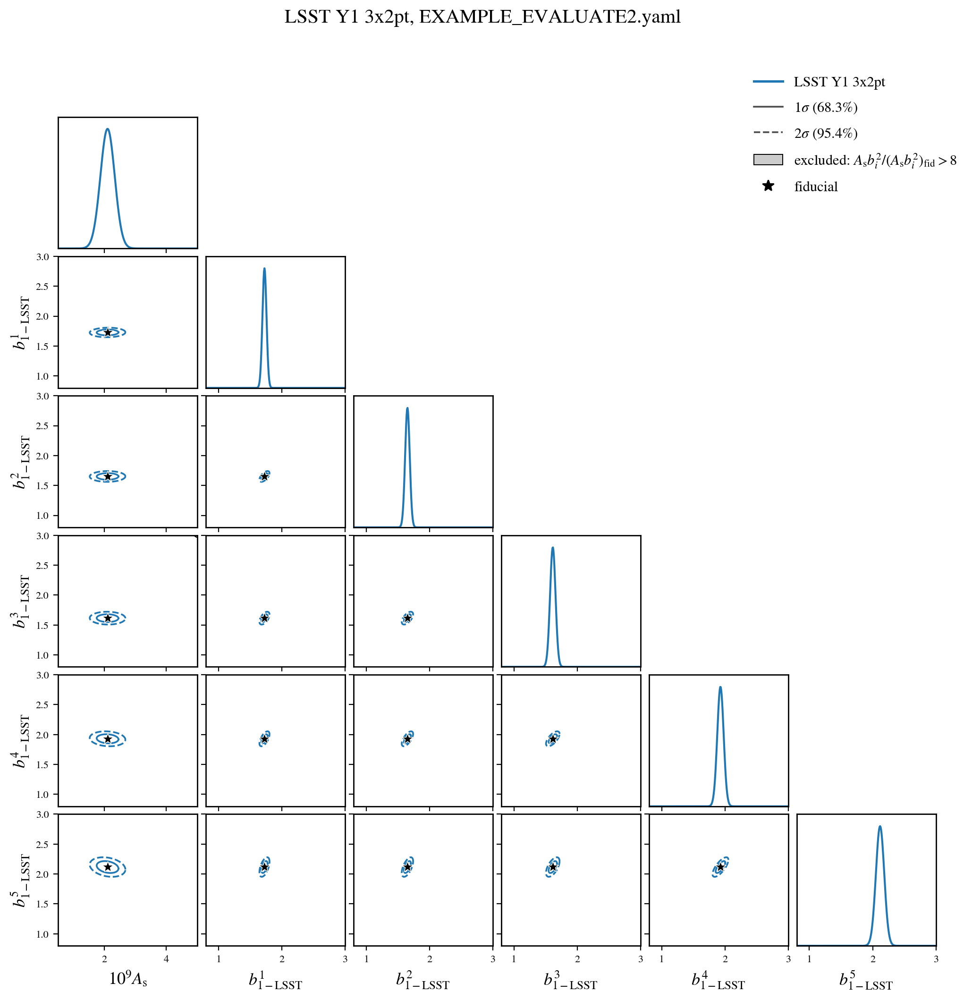

In [52]:
def check_amplitude_cut(cut):
    '''Check that the yaml's amplitude_cut prior keeps ratios up to cut.

    The prior is a lambda string that cobaya evaluates with numpy as np.
    Evaluating it with one bias just inside and just outside the cut, A_s
    and the other biases at the fiducial, checks the cut and the
    fiducial bias the lambda holds for every lens bin.

    Arguments:
      cut = the amplitude ratio the figure shades above.

    Raises:
      ValueError naming the lens bin where the yaml's prior disagrees.
    '''
    amplitude_prior = eval(example['prior']['amplitude_cut'], {'np': np})
    for bias_name in BIAS_NAMES:
        for factor, expected in ((0.999, 0.0), (1.001, -np.inf)):
            arguments = {'As_1e9': fiducial['As_1e9']}
            for other in BIAS_NAMES:
                arguments[other] = fiducial[other]
            arguments[bias_name] = fiducial[bias_name]*np.sqrt(factor*cut)
            if amplitude_prior(**arguments) != expected:
                raise ValueError(f'at the amplitude ratio {factor*cut:g} of '
                                 f'{bias_name} the yaml prior returns '
                                 f'{amplitude_prior(**arguments)}, not '
                                 f'{expected}: set AMPLITUDE_CUT and the '
                                 'fiducial to the yaml amplitude_cut')


check_amplitude_cut(AMPLITUDE_CUT)
amplitude_boxes = {}
for name in ['As_1e9'] + BIAS_NAMES:
    prior = example_prior(name)
    amplitude_boxes[name] = (prior['min'], prior['max'])
# the legends of the cnu Fisher figures write 68.3%, and LaTeX reads % as a
# comment: the figures of this section use matplotlib's mathtext
matplotlib.rcParams['text.usetex'] = False
fig, axes = cnu.plot_Fisher_amplitude_cut(
    F=[F_3x2pt], names=[FISHER_NAMES], fiducial=fiducial,
    amplitude='As_1e9', biases=BIAS_NAMES, boxes=amplitude_boxes,
    labels=FISHER_LABELS, cut=AMPLITUDE_CUT,
    chain_names=['LSST Y1 3x2pt'], show=None)
fig.suptitle('LSST Y1 3x2pt, EXAMPLE_EVALUATE2.yaml', fontsize=15)
plt.show()

### The cosmological prior walls

Gray: outside the $\Omega_\mathrm{m}$ and $w_0$ boxes and the $w_0 + w_a$ wall of the
yaml.

The $w_0 + w_a < 0$ wall is a physical prior, not one of the numerical cuts: in the
$w_0$–$w_a$ parametrization the equation of state approaches
$w(a \to 0) = w_0 + w_a$, so the wall keeps dark energy subdominant at early times.
The 3×2pt data alone do not exclude $w_0 + w_a > 0$, so this wall does shape a
3×2pt-only posterior.

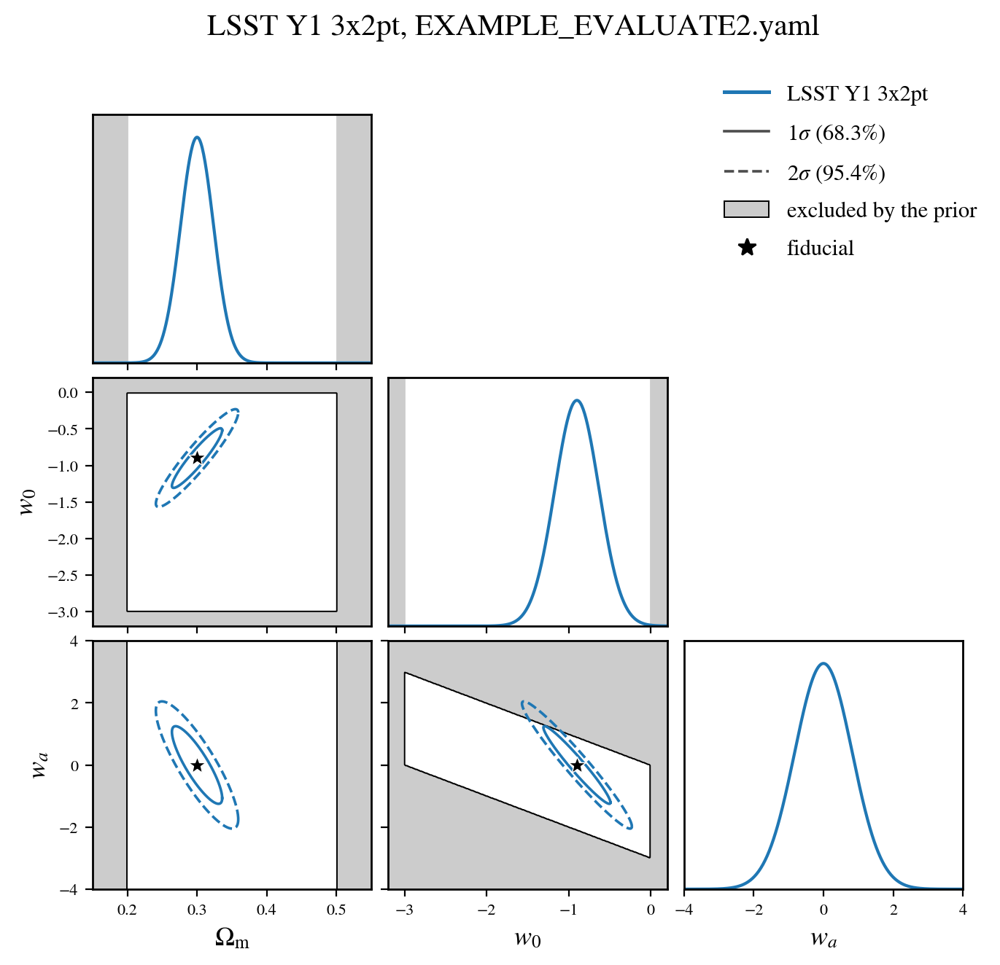

In [53]:
wall_boxes = {}
for name, yaml_name in (('omegam', 'omegam'), ('w0', 'w')):
    prior = example_prior(yaml_name)
    wall_boxes[name] = (prior['min'], prior['max'])
# the w0pwa box is the linear wall min <= w0 + wa <= max
w0pwa_prior = example_prior('w0pwa')
walls = [({'w0': 1.0, 'wa': 1.0}, w0pwa_prior['min'], w0pwa_prior['max'])]
matplotlib.rcParams['text.usetex'] = False
fig, axes = cnu.plot_Fisher_prior_walls(
    F=[F_3x2pt], names=[FISHER_NAMES], fiducial=fiducial,
    params=['omegam', 'w0', 'wa'],
    ranges={'omegam': (0.15, 0.55), 'w0': (-3.2, 0.2), 'wa': (-4.0, 4.0)},
    boxes=wall_boxes, walls=walls, labels=FISHER_LABELS,
    chain_names=['LSST Y1 3x2pt'], show=None)
fig.suptitle('LSST Y1 3x2pt, EXAMPLE_EVALUATE2.yaml', fontsize=15)
plt.show()

### The 2σ contours against the cuts

The largest amplitude ratio on each $2\sigma$ contour, and the range each walled
quantity spans on them:

| Quantity | $2\sigma$ range | Prior cut |
|---|---|---|
| $(A_\mathrm{s}/A_\mathrm{s,fid})(b_i/b_{i,\mathrm{fid}})^2$ | up to 1.29–1.32 per bin | $\leq 8$ |
| $\Omega_\mathrm{m}$ | $[0.24, 0.36]$ | box $[0.2, 0.5]$ |
| $w_0$ | $[-1.57, -0.23]$ | box $[-3, -0.01]$ |
| $w_0 + w_a$ | $[-2.32, 0.52]$ | walls $-3$ and $-0.01$ |

$\Omega_\mathrm{m}$ and $w_0$ stay well inside their boxes, and $w_0 + w_a$ stays
clear of $-3$. The one wall inside the $2\sigma$ region is the physical one at
$w_0 + w_a < 0$, which sits $1.56\sigma$ above the fiducial $w_0 + w_a = -0.9$.

In [54]:
def two_sigma_contour(name_x, name_y, n_points=3600):
    '''Return the points of the 2 sigma contour of one parameter pair.

    The dashed curve of the figures: (p - p_fid)^T C2^-1 (p - p_fid) =
    6.18 (95.4% of a two-dimensional Gaussian), with C2 the 2x2 block of
    covariance_3x2pt. With C2 = L L^T (Cholesky), the point at angle t is
    p_fid + sqrt(6.18) L (cos t, sin t).

    Arguments:
      name_x, name_y = the two parameter names (FISHER_NAMES entries).
      n_points = points along the contour.

    Returns:
      (x, y): two 1D arrays of n_points values of name_x and name_y.
    '''
    rows = [FISHER_NAMES.index(name_x), FISHER_NAMES.index(name_y)]
    cholesky = np.linalg.cholesky(covariance_3x2pt[np.ix_(rows, rows)])
    angle = np.linspace(0.0, 2.0*np.pi, n_points)
    circle = np.sqrt(6.18)*np.vstack([np.cos(angle), np.sin(angle)])
    offsets = cholesky @ circle
    return fiducial[name_x] + offsets[0], fiducial[name_y] + offsets[1]


print(f'largest amplitude ratio on the 2 sigma contours (cut {AMPLITUDE_CUT:g}):')
for bias_name in BIAS_NAMES:
    As_values, bias_values = two_sigma_contour('As_1e9', bias_name)
    ratio = ((As_values/fiducial['As_1e9'])
             *(bias_values/fiducial[bias_name])**2)
    print(f'  {bias_name}: {ratio.max():.2f}')

print('range on the 2 sigma contours, against the walls:')
omegam_values, w0_values = two_sigma_contour('omegam', 'w0')
print(f'  omegam: [{omegam_values.min():.3f}, {omegam_values.max():.3f}], '
      f'box {wall_boxes["omegam"]}')
print(f'  w0: [{w0_values.min():.3f}, {w0_values.max():.3f}], '
      f'box {wall_boxes["w0"]}')
w0_values, wa_values = two_sigma_contour('w0', 'wa')
w0pwa_values = w0_values + wa_values
print(f'  w0 + wa: [{w0pwa_values.min():.3f}, {w0pwa_values.max():.3f}], '
      f'wall ({w0pwa_prior["min"]}, {w0pwa_prior["max"]})')

# the LaTeX setting of the rest of the notebook
matplotlib.rcParams['text.usetex'] = USETEX_OUTSIDE_SECTION

largest amplitude ratio on the 2 sigma contours (cut 8):
  LSST_B1_1: 1.30
  LSST_B1_2: 1.31
  LSST_B1_3: 1.32
  LSST_B1_4: 1.30
  LSST_B1_5: 1.29
range on the 2 sigma contours, against the walls:
  omegam: [0.241, 0.359], box (0.2, 0.5)
  w0: [-1.570, -0.230], box (-3, -0.01)
  w0 + wa: [-2.315, 0.515], wall (-3, -0.01)
